# Complete FOM → ROM → ROM-step GNN notebook

This notebook implements a complete conceptual pipeline for interconnected power-station components under base excitation.

The key correction in this version is that the ROM is **not** used only as a static descriptor. Instead, the ROM is used as a **differentiable one-step dynamic operator**.

At every time step, the model follows this sequence:

$$\mathrm{message\ passing}\;\longrightarrow\;\hat f_i^{\mathrm{cable}}(t+1)\;\longrightarrow\;\mathrm{Newmark\ ROM\ time\ step}\;\longrightarrow\;\hat q_i(t+1),\ \hat{\dot q}_i(t+1),\ \hat u_i^{\mathrm{top}}(t+1).$$

The full hierarchy is:

$$\boxed{\mathrm{Full\ order\ FE\ reference}}\;\longrightarrow\;\boxed{\mathrm{Component\ modal\ ROMs}}\;\longrightarrow\;\boxed{\mathrm{GNN + differentiable\ ROM\ decoder}}.$$

## What is used as the full-order model?

Each component is represented by an Abaqus-exported component FE model. Each component has its own full-order matrices:

$$M_i,\quad C_i,\quad K_i.$$

The components are connected in a line through cable-like spring-damper links acting between their top/interface DOFs.

For one isolated component, the full-order equation can be written as:

$$M_i \ddot u_i + C_i \dot u_i + K_i u_i = -M_i r_i a_g(t) + f_i^{\mathrm{cable}}(t).$$

Here, \(a_g(t)\) is the ground acceleration, \(r_i\) is the ground-acceleration influence vector, and \(f_i^{\mathrm{cable}}(t)\) is the interaction force transmitted through the cable connections.

There is **no independent top force** in this base-excited setting.

The cable between neighboring components is modeled as a spring-damper link:

$$f_{ij}(t) = k_c\left(u_j^{\mathrm{top}}(t)-u_i^{\mathrm{top}}(t)\right)+c_c\left(\dot u_j^{\mathrm{top}}(t)-\dot u_i^{\mathrm{top}}(t)\right).$$

If the cable terms are assembled directly into the global damping and stiffness matrices, the full coupled system is:

$$M^{\mathrm{FOM}}\ddot u + C^{\mathrm{FOM}}\dot u + K^{\mathrm{FOM}}u = -M^{\mathrm{FOM}}r a_g(t).$$

This coupled full-order dynamic problem is solved conventionally using Newmark integration. Its top-DOF response is used as the reference solution:

$$u_{i,\mathrm{FOM}}^{\mathrm{top}}(t),\quad \dot u_{i,\mathrm{FOM}}^{\mathrm{top}}(t),\quad \ddot u_{i,\mathrm{FOM}}^{\mathrm{top}}(t).$$

The section-moment reference is computed as an additional diagnostic quantity. For component \(i\), define \(h_i\) as the height-arm vector relative to the selected section node. The absolute acceleration is:

$$\ddot u_i^{\mathrm{abs}}(t)=\ddot u_i(t)+r_i a_g(t).$$

Then the section moment demand is approximated from the inertia-force resultant:

$$m_{i,\mathrm{true}}(t)=\left(\ddot u_i^{\mathrm{abs}}(t)\right)^T M_i h_i.$$

This quantity is stored as `moment_true`. It is not used in the current training loss; it is used to evaluate whether the learned rollout gives reasonable engineering response quantities.

## What is used as the ROM?

For each individual component, a modal reduced-order model is constructed from the isolated component FE model.

The displacement field of component \(i\) is approximated using the retained modes:

$$u_i(t) \approx \Phi_i q_i(t).$$

The reduced-order model is:

$$M_{r,i}\ddot q_i + C_{r,i}\dot q_i + K_{r,i}q_i = B_i^{\mathrm{cable}} f_i^{\mathrm{cable}} - B_i^{\mathrm{ground}} a_g.$$

These reduced vectors come directly from Galerkin projection of the component FOM. Start from the component equation with a scalar interface force applied at the top/interface DOF:

$$M_i\ddot u_i+C_i\dot u_i+K_i u_i=e_i^{\mathrm{top}}f_i^{\mathrm{cable}}-M_i r_i a_g,$$

where \(e_i^{\mathrm{top}}\) is a unit selector vector whose only nonzero entry is at the top/interface DOF. Substitute \(u_i\approx \Phi_i q_i\), premultiply by \(\Phi_i^T\), and obtain:

$$\Phi_i^T M_i\Phi_i\ddot q_i+\Phi_i^T C_i\Phi_i\dot q_i+\Phi_i^T K_i\Phi_i q_i=\Phi_i^T e_i^{\mathrm{top}}f_i^{\mathrm{cable}}-\Phi_i^T M_i r_i a_g.$$

Therefore:

$$M_{r,i}=\Phi_i^T M_i\Phi_i,\quad C_{r,i}=\Phi_i^T C_i\Phi_i,\quad K_{r,i}=\Phi_i^T K_i\Phi_i,$$

$$B_i^{\mathrm{cable}}=\Phi_i^T e_i^{\mathrm{top}},\quad B_i^{\mathrm{ground}}=\Phi_i^T M_i r_i.$$

The top-response reconstruction map is the row of the modal basis evaluated at the top/interface DOF:

$$H_i=e_i^{\mathrm{top},T}\Phi_i,$$

The top displacement, velocity, and acceleration are reconstructed as:

$$u_i^{\mathrm{top}} = H_i q_i.$$

$$\dot u_i^{\mathrm{top}} = H_i \dot q_i.$$

$$\ddot u_i^{\mathrm{top}} = H_i \ddot q_i.$$

For the section-moment diagnostic, the ROM stores two additional maps:

The FOM moment approximation uses the absolute acceleration inertia resultant:

$$m_i(t)=\left(\ddot u_i(t)+r_i a_g(t)\right)^T M_i h_i.$$

Using \(\ddot u_i\approx \Phi_i\ddot q_i\), this becomes:

$$m_i(t)\approx \ddot q_i(t)^T\Phi_i^T M_i h_i+a_g(t)r_i^T M_i h_i.$$

Thus:

$$B_i^{\mathrm{moment}}=\Phi_i^T M_i h_i,$$

$$G_i^{\mathrm{moment}}=r_i^T M_i h_i.$$

These maps reconstruct the moment from the predicted modal acceleration and ground input:

$$\hat m_i(t+1)=\hat{\ddot q}_i(t+1)^T B_i^{\mathrm{moment}}+a_g(t+1)G_i^{\mathrm{moment}}.$$

## What does the GNN learn?

The GNN does not learn the full local structural dynamics. Those dynamics are already represented by the component ROM.

Instead, the GNN learns the effective graph-mediated cable/interface force used to advance the state from \(t\) to \(t+1\):

$$\hat f_i^{\mathrm{cable}}(t+1) = \mathrm{GNN}_\theta\left(q_i(t),\dot q_i(t),a_g(t+1),\mathrm{ROM\ descriptors},\mathrm{graph}\right).$$

The reduced external force at the next step is:

$$F_{r,i}(t+1)=B_i^{\mathrm{cable}}\hat f_i^{\mathrm{cable}}(t+1)-B_i^{\mathrm{ground}}a_g(t+1).$$

The ROM dynamics are:

$$M_{r,i}\ddot q_i+C_{r,i}\dot q_i+K_{r,i}q_i=F_{r,i}.$$

The modal state is advanced by a differentiable Newmark average-acceleration step with \(\beta=1/4\) and \(\gamma=1/2\):

$$K_{\mathrm{eff},i}=K_{r,i}+\frac{\gamma}{\beta\Delta t}C_{r,i}+\frac{1}{\beta\Delta t^2}M_{r,i}.$$

$$q_i(t+1)=K_{\mathrm{eff},i}^{-1}R_{\mathrm{eff},i}(t+1).$$

$$\ddot q_i(t+1)=\frac{1}{\beta\Delta t^2}\left(q_i(t+1)-q_i(t)\right)-\frac{1}{\beta\Delta t}\dot q_i(t)-\left(\frac{1}{2\beta}-1\right)\ddot q_i(t).$$

$$\dot q_i(t+1)=\dot q_i(t)+\Delta t\left((1-\gamma)\ddot q_i(t)+\gamma\ddot q_i(t+1)\right).$$

Finally, the predicted top response is reconstructed as:

$$\hat u_i^{\mathrm{top}}(t+1) = H_i q_i(t+1).$$

$$\hat{\dot u}_i^{\mathrm{top}}(t+1) = H_i \dot q_i(t+1).$$

$$\hat{\ddot u}_i^{\mathrm{top}}(t+1) = H_i \ddot q_i(t+1).$$

## What is the training target?

The training target is always the **full-order reference solution**, not the ROM solution.

The coupled ROM solution is used only as a physics baseline. Cable force and section moment are diagnostic quantities in this notebook.

## 0. Imports and reproducibility

In [1]:
import math
import random
from dataclasses import dataclass

import numpy as np
import scipy.linalg as la
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

import pickle
from pathlib import Path


SEED = 2026
np.random.seed(SEED)
random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


## 1. Global settings

The default settings are intentionally small so the notebook runs quickly in Colab. Increase `N_TRAIN`, `T`, `EPOCHS`, and `STEPS_PER_EPOCH` once the pipeline is working.

In [2]:
FAST_RUN = False

N_TRAIN = 100
N_VAL = 20
T = 3000
DT = 0.01

EPOCHS = 300
STEPS_PER_EPOCH = 5000
VAL_CHECKS = 6000

R_MODES = 4
HIDDEN = 128
N_LAYERS = 3

LR = 5.0e-4
WEIGHT_DECAY = 1.0e-5
GRAD_CLIP_NORM = 1.0
COSINE_T_MAX = EPOCHS
COSINE_ETA_MIN = 1.0e-6

print({
    "N_TRAIN": N_TRAIN,
    "N_VAL": N_VAL,
    "T": T,
    "DT": DT,
    "R_MODES": R_MODES,
    "HIDDEN": HIDDEN,
    "N_LAYERS": N_LAYERS,
    "EPOCHS": EPOCHS,
    "STEPS_PER_EPOCH": STEPS_PER_EPOCH,
    "VAL_CHECKS": VAL_CHECKS,
    "LR": LR,
    "WEIGHT_DECAY": WEIGHT_DECAY,
    "GRAD_CLIP_NORM": GRAD_CLIP_NORM,
    "COSINE_T_MAX": COSINE_T_MAX,
    "COSINE_ETA_MIN": COSINE_ETA_MIN,
})


{'N_TRAIN': 100, 'N_VAL': 20, 'T': 3000, 'DT': 0.01, 'R_MODES': 4, 'HIDDEN': 128, 'N_LAYERS': 3, 'EPOCHS': 300, 'STEPS_PER_EPOCH': 5000, 'VAL_CHECKS': 6000, 'LR': 0.0005, 'WEIGHT_DECAY': 1e-05, 'GRAD_CLIP_NORM': 1.0, 'COSINE_T_MAX': 300, 'COSINE_ETA_MIN': 1e-06}


## 2. Define component FOM types

The three component types are deliberately simple but heterogeneous. Later, each item can be replaced by a proper FE model of a transformer, breaker, reactor, or other substation component.

The rest of the pipeline only needs each component to provide \(M_i\), \(C_i\), \(K_i\), a top/interface DOF, and a ground-acceleration influence vector.

In [3]:
@dataclass
class AbaqusComponentFOM:
    name: str              # Abaqus file name prefix
    equipment: str         # equipment name
    zeta: float            # Rayleigh damping target ratio
    target_set: str = "Target_node"
    moment_section_set: str = "Moment_section_node"
    height_axis: int = 1
    modes: tuple = (0, 2)  # modes to be used for training
    
    

COMPONENT_LIBRARY = [
    AbaqusComponentFOM(
        name="PL1",
        equipment="Post insulator 1",
        zeta=0.015,
        modes=(0, 2)
    ),
    AbaqusComponentFOM(
        name="PL2",
        equipment="Post insulator 2",
        zeta=0.020,
        modes=(0, 2)
    ),
    AbaqusComponentFOM(
        name="BS",
        equipment="Bypass switch",
        zeta=0.025,
        modes=(0, 3)
    ),
]


for i, comp in enumerate(COMPONENT_LIBRARY):
    print(i, comp)

0 AbaqusComponentFOM(name='PL1', equipment='Post insulator 1', zeta=0.015, target_set='Target_node', moment_section_set='Moment_section_node', height_axis=1, modes=(0, 2))
1 AbaqusComponentFOM(name='PL2', equipment='Post insulator 2', zeta=0.02, target_set='Target_node', moment_section_set='Moment_section_node', height_axis=1, modes=(0, 2))
2 AbaqusComponentFOM(name='BS', equipment='Bypass switch', zeta=0.025, target_set='Target_node', moment_section_set='Moment_section_node', height_axis=1, modes=(0, 3))


## 3. Beam finite element model for one component

Each beam node has two DOFs, \(w\) and \(\theta\). The base is clamped, so the base displacement and rotation are removed.

The top lateral displacement DOF is used as the output DOF and as the interface DOF for cable connections.

In [4]:
def read_mtx(filename):
    """
    read Abaqus MATRIX INPUT file, which is a text file with the following format:
        node1, dof1, node2, dof2, value
    
    returns: 
        entries list [(node1,dof1,node2,dof2,value), ...]
    """
    entries = []
    with open(filename, 'r') as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('**'):
              continue

            parts = [p.strip() for p in line.split(',')]
            if len(parts) < 5:
              continue

            entries.append((int(parts[0]), int(parts[1]), int(parts[2]), int(parts[3]), float(parts[4])))
    return entries


def build_dof_index(entries_list):
    """
    from entries list collect all unique (node, dof) pairs,
    build a unified, sorted index mapping to ensure K and M use the same numbering.
    """
    nodes_dofs = set()
    for entries in entries_list:
        for n1, d1, n2, d2, val in entries:
            nodes_dofs.add((n1, d1))
            nodes_dofs.add((n2, d2))
    sorted_dofs = sorted(nodes_dofs)   # sorted_dofs = [(1,1),(1,2),(1,3)]

    dof_index = {}
    for i, nd in enumerate(sorted_dofs):
        dof_index[nd] = i

    return dof_index, sorted_dofs


def assemble_matrix(entries, dof_index, n):
    mat = np.zeros((n, n))
    for n1, d1, n2, d2, val in entries:
        i, j = dof_index[(n1, d1)], dof_index[(n2, d2)]
        mat[i, j] = val
        mat[j, i] = val
    return mat


def remove_constrained_dofs(K, M, sorted_dofs, threshold=1e20):
    diagK = np.diag(K)
    retained_idx = np.where(diagK <= threshold)[0]

    retained_dofs = []
    for i in retained_idx:
        retained_dofs.append(sorted_dofs[i])

    deleted_dofs = []
    for i in range(len(sorted_dofs)):
        if i not in retained_idx:
            deleted_dofs.append(sorted_dofs[i])

    K_new = K[np.ix_(retained_idx, retained_idx)]
    M_new = M[np.ix_(retained_idx, retained_idx)]

    return K_new, M_new, retained_dofs, deleted_dofs

def rayleigh_damping_from_modes(M, K, zeta=0.02, modes=(0, 2)):
    """
    Compute C = alpha M + beta K so that two selected modes approximately have damping ratio zeta.
    """
    evals = la.eigvalsh(K, M)
    omegas = np.sqrt(np.maximum(evals, 1e-12))

    w1 = omegas[modes[0]]
    w2 = omegas[modes[1]]

    A = np.array(
        [
            [1.0 / (2.0 * w1), w1 / 2.0],
            [1.0 / (2.0 * w2), w2 / 2.0],
        ]
    )

    alpha, beta = np.linalg.solve(A, np.array([zeta, zeta]))
    C = alpha * M + beta * K

    return C, alpha, beta, omegas


def get_node_id_from_set(inp_filename, set_name):
    """from .inp to find the node index of Nset"""

    found_set = False

    with open(inp_filename, 'r') as f:
        for line in f:
            line = line.strip()

            # target Nset
            if line.upper().startswith("*NSET") and f"NSET={set_name.upper()}" in line.upper():
                found_set = True
                continue

            # read node id from the set
            if found_set:
                # stop reading when we encounter another *NSET or *ELEMENT or *MATERIAL or *STEP
                if line.startswith("*"):
                    break

                # read node id from the line
                node = int(line.split(",")[0].strip())
                return node

    return None

def read_node_coords_from_inp(inp_filename):
    """
    Read node coordinates from the first *Node block.
    Returns: node_id -> np.array([x, y, z])
    """
    node_coords = {}
    found_node = False

    with open(inp_filename, "r") as f:
        for line in f:
            line = line.strip()

            if not line or line.startswith("**"):
                continue

            if line.upper().startswith("*NODE"):
                found_node = True
                continue

            if found_node:
                if line.startswith("*"):
                    break

                parts = [p.strip() for p in line.split(",")]

                if len(parts) >= 4:
                    node_id = int(parts[0])
                    node_coords[node_id] = np.array(
                        [
                            float(parts[1]),
                            float(parts[2]),
                            float(parts[3]),
                        ]
                    )
    return node_coords

def compute_delta_h(node_coords, section_node_id, height_axis):
  h_section = node_coords[section_node_id][height_axis]
  delta_h = {}

  for node_id, xyz in node_coords.items():
      delta_h[node_id] = xyz[height_axis] - h_section

  return delta_h

_COMPONENT_FOM_CACHE = {}

def build_component_fom(comp, cache=True):
    """
    process abaqus matrice to build component fom.

    Returns:
      M, C, K: component matrices after deleting the boundray node at the base
      top_dof: local top displacement DOF index
      r: ground-acceleration influence vector
      freqs_hz: natural frequencies of isolated component
    """

    cache_key = (comp.name,comp.equipment,comp.zeta,comp.target_set,comp.modes)

    if cache and cache_key in _COMPONENT_FOM_CACHE:
        return _COMPONENT_FOM_CACHE[cache_key]
    
    stif_file = f"{comp.name}_STIF1.mtx"
    mass_file = f"{comp.name}_MASS1.mtx"
    input_file  = f"{comp.name}.inp"

    stif_entries = read_mtx(stif_file)
    mass_entries = read_mtx(mass_file)

    dof_index, sorted_dofs = build_dof_index([stif_entries, mass_entries])
    ndof = len(sorted_dofs)

    K_full = assemble_matrix(stif_entries, dof_index, ndof)
    M_full = assemble_matrix(mass_entries, dof_index, ndof)

    K, M, sorted_dofs_clean, _ = remove_constrained_dofs(K_full, M_full, sorted_dofs)
    # print(f"ndof_original: {ndof}, ndof_retained: {len(sorted_dofs_clean)}")

    C, alpha, beta, omegas = rayleigh_damping_from_modes(M, K, comp.zeta, comp.modes)
    freqs_hz = omegas / (2 * np.pi)

    # transform sorted_dofs_clean to DataFrame
    dof_map = pd.DataFrame(sorted_dofs_clean, columns=['node_id', 'dof_id'])

    target_node_id = get_node_id_from_set(input_file, comp.target_set)

    dof_map = pd.DataFrame(sorted_dofs_clean, columns=['node_id', 'dof_id'])

    # find the index of the target node's DOF
    top_dof = dof_map.index[(dof_map['node_id'] == target_node_id) & (dof_map['dof_id'] == 1)][0]

    # influence vector r_vector (apply unit load at nodes in X direction)
    r_vector = (dof_map['dof_id'] == 1).astype(int).values

    node_coords = read_node_coords_from_inp(input_file)

    section_node_id = get_node_id_from_set(input_file, comp.moment_section_set)

    delta_h = compute_delta_h(node_coords, section_node_id, comp.height_axis)  # Assuming z-axis is the height axis

    h_vector = np.zeros(len(dof_map))

    for idx, (node_id, dof_id) in dof_map[["node_id", "dof_id"]].iterrows():
      if dof_id == 1 and delta_h.get(node_id, 0.0) > 0.0:
        h_vector[idx] = delta_h[node_id]

    data = {
        "M": M,
        "C": C,
        "K": K,
        "top_dof": top_dof,
        "r": r_vector,
        "h_vector": h_vector,
        "freqs_hz": freqs_hz,
        "alpha": alpha,
        "beta": beta,
    }

    if cache:
        _COMPONENT_FOM_CACHE[cache_key] = data

    return data



for comp in COMPONENT_LIBRARY:
    fom = build_component_fom(comp)
    print(comp.name)
    print("  ndof:", fom["M"].shape[0])
    print("  first frequencies [Hz]:", np.round(fom["freqs_hz"][:8], 3))
    print("  top_dof:", fom["top_dof"])
    print("  h_vector:", fom["h_vector"][:10])

PL1
  ndof: 264
  first frequencies [Hz]: [ 0.884  0.884  5.397  5.397 13.425 13.425 18.706 18.706]
  top_dof: 30
  h_vector: [12.2700005  0.         0.         0.         0.         0.
 12.2700005  0.         0.         0.       ]
PL2
  ndof: 384
  first frequencies [Hz]: [ 2.464  2.464 10.82  10.82  18.029 18.029 30.159 44.311]
  top_dof: 30
  h_vector: [6.69999978 0.         0.         0.         0.         0.
 6.69999978 0.         0.         0.        ]
BS
  ndof: 858
  first frequencies [Hz]: [ 0.496  0.518  1.281  2.693  5.589  8.654 13.821 14.361]
  top_dof: 78
  h_vector: [ 9.868      0.         0.         0.         0.         0.
  9.868      0.         0.        10.7679996]


## 4. Assemble the coupled FOM system

The components are connected in a line. Neighboring top DOFs are coupled by cable-like spring-damper links.

For one cable, the interaction force is:

$$f_{ij}(t) = k_c\left(u_j^{\mathrm{top}}(t)-u_i^{\mathrm{top}}(t)\right)+c_c\left(\dot u_j^{\mathrm{top}}(t)-\dot u_i^{\mathrm{top}}(t)\right).$$

This is assembled directly into the global \(K\) and \(C\) matrices.

In [5]:
KC_RANGE = (5.0e3, 2.0e4)
CC_RANGE =(60.0, 300.0)

def line_edges(N, rng, kc_range=KC_RANGE, cc_range=CC_RANGE):
    """
    Build a line graph with N components.
    """
    edges = [(i, i + 1) for i in range(N - 1)]
    kc = rng.uniform(kc_range[0], kc_range[1], size=N - 1)
    cc = rng.uniform(cc_range[0], cc_range[1], size=N - 1)
    return edges, kc, cc


def assemble_global_fom(component_type_ids, component_library, edges, kc, cc):
    """
    Assemble the coupled full-order system.
    """
    M_blocks = []
    C_blocks = []
    K_blocks = []
    r_blocks = []

    component_data = []
    component_slices = []
    top_dofs = []

    ndof_total = 0

    for type_id in component_type_ids:
        comp = component_library[int(type_id)]
        data = build_component_fom(comp)

        n = data["M"].shape[0]
        sl = slice(ndof_total, ndof_total + n)

        M_blocks.append(data["M"])
        C_blocks.append(data["C"])
        K_blocks.append(data["K"])
        r_blocks.append(data["r"])

        component_data.append(data)
        component_slices.append(sl)
        top_dofs.append(ndof_total + data["top_dof"])

        ndof_total += n

    M = la.block_diag(*M_blocks)
    C = la.block_diag(*C_blocks)
    K = la.block_diag(*K_blocks)

    r_global = np.concatenate(r_blocks)
    top_dofs = np.array(top_dofs, dtype=int)

    for e, (i, j) in enumerate(edges):
        p = top_dofs[i]
        q = top_dofs[j]

        for A, value in [(K, kc[e]), (C, cc[e])]:
            A[p, p] += value
            A[q, q] += value
            A[p, q] -= value
            A[q, p] -= value

    return {
        "M": M,
        "C": C,
        "K": K,
        "top_dofs": top_dofs,
        "r_global": r_global,
        "component_data": component_data,
        "component_slices": component_slices,
        "component_type_ids": np.asarray(component_type_ids, dtype=int),
        "edges": edges,
        "kc": kc,
        "cc": cc,
    }

## 5. Base excitation and conventional Newmark solver

For pure base excitation, the global FOM force is:

$$F(t) = -M r a_g(t).$$

The FOM reference is then obtained by solving:

$$M\ddot u + C\dot u + Ku = F(t).$$

In [6]:
G_ACCEL = 9.80665
GROUND_MOTION_MATCH_ITER = 8


def _smoothstep(x):
    x = np.clip(x, 0.0, 1.0)
    return x * x * (3.0 - 2.0 * x)


def _ieee693_rrs_g(freq_hz):
    """
    Approximate IEEE 693 high-level horizontal RRS in g.
    """
    f_anchor = np.array([0.10, 0.20, 0.50, 1.10, 8.00, 33.00, 100.00])
    sa_anchor = np.array([0.15, 0.225, 0.65, 1.65, 1.65, 0.50, 0.50])
    freq_hz = np.maximum(np.asarray(freq_hz, dtype=float), f_anchor[0])
    return np.exp(np.interp(np.log(freq_hz), np.log(f_anchor), np.log(sa_anchor)))


def _motion_envelope(time):
    duration = max(float(time[-1] - time[0]), 1e-12)
    tau = (time - time[0]) / duration

    env = np.full_like(tau, 0.03)
    rise = (tau >= 0.10) & (tau < 0.25)
    decay = (tau >= 0.65) & (tau < 0.90)

    env[rise] = 0.03 + 0.97 * _smoothstep((tau[rise] - 0.10) / 0.15)
    env[(tau >= 0.25) & (tau < 0.65)] = 1.0
    env[decay] = 0.03 + 0.97 * (1.0 - _smoothstep((tau[decay] - 0.65) / 0.25))
    return env


def _cosine_taper(n, frac=0.03):
    taper = np.ones(n)
    m = int(round(frac * n))
    if m > 0:
        ramp = 0.5 * (1.0 - np.cos(np.linspace(0.0, np.pi, m)))
        taper[:m] = ramp
        taper[-m:] = ramp[::-1]
    return taper


def _highpass_fft(x, dt, corner_hz=0.10):
    n = len(x)
    freqs = np.fft.rfftfreq(n, dt)
    scale = np.ones_like(freqs)
    scale[freqs <= corner_hz] = 0.0

    transition = (freqs > corner_hz) & (freqs < 2.0 * corner_hz)
    scale[transition] = 0.5 * (1.0 - np.cos(np.pi * (freqs[transition] - corner_hz) / corner_hz))

    return np.fft.irfft(np.fft.rfft(x) * scale, n=n)


def _response_spectrum_pseudo_accel_g(accel_g, dt, freq_hz, damping=0.02):
    ag = np.asarray(accel_g, dtype=float) * G_ACCEL
    sa = np.empty(len(freq_hz), dtype=float)

    beta = 0.25
    gamma = 0.5
    a0 = 1.0 / (beta * dt * dt)
    a1 = gamma / (beta * dt)
    a2 = 1.0 / (beta * dt)
    a3 = 1.0 / (2.0 * beta) - 1.0
    a4 = gamma / beta - 1.0
    a5 = dt * (gamma / (2.0 * beta) - 1.0)

    for i, f in enumerate(freq_hz):
        w = 2.0 * np.pi * f
        c = 2.0 * damping * w
        k = w * w
        k_eff = k + a0 + a1 * c

        u = 0.0
        v = 0.0
        acc_rel = -ag[0] - c * v - k * u
        max_abs_u = 0.0

        for ag_i in ag[1:]:
            p_eff = -ag_i + a0 * u + a2 * v + a3 * acc_rel + c * (a1 * u + a4 * v + a5 * acc_rel)
            u_new = p_eff / k_eff
            acc_new = a0 * (u_new - u) - a2 * v - a3 * acc_rel
            v_new = v + dt * ((1.0 - gamma) * acc_rel + gamma * acc_new)

            u, v, acc_rel = u_new, v_new, acc_new
            max_abs_u = max(max_abs_u, abs(u))

        sa[i] = (w * w * max_abs_u) / G_ACCEL

    return sa


def _match_spectrum_frequency_domain(accel_g, dt, freq_match, target_sa_g, n_iter=8, damping=0.02):
    n = len(accel_g)
    fft_freq = np.fft.rfftfreq(n, dt)
    taper = _cosine_taper(n, frac=0.03)
    x = np.asarray(accel_g, dtype=float).copy()

    for _ in range(n_iter):
        current_sa = _response_spectrum_pseudo_accel_g(x, dt, freq_match, damping=damping)
        ratio = target_sa_g / np.maximum(current_sa, 1e-8)
        ratio = np.clip(ratio, 1.0 / 1.60, 1.60)

        log_scale = np.interp(
            np.log(np.maximum(fft_freq, freq_match[0])),
            np.log(freq_match),
            np.log(ratio),
            left=np.log(ratio[0]),
            right=np.log(ratio[-1]),
        )
        scale = np.exp(log_scale)
        scale[fft_freq < freq_match[0]] = 1.0
        scale[fft_freq > freq_match[-1]] = 1.0
        scale[0] = 0.0

        x = np.fft.irfft(np.fft.rfft(x) * scale, n=n)
        x = _highpass_fft(x * taper, dt)
        x -= np.mean(x)

    return x


def random_ground_acceleration(T, dt, rng, amplitude=1.0):
    """
    Random IEEE 693-style horizontal ground acceleration in m/s^2.
    Each record is spectrum-matched for GROUND_MOTION_MATCH_ITER iterations.
    """
    T = int(T)
    if T <= 1:
        return np.zeros(T)

    time = np.arange(T) * dt
    freqs = np.fft.rfftfreq(T, dt)
    band = (freqs >= 0.20) & (freqs <= min(50.0, 0.45 / dt))

    spectrum_amp = np.zeros_like(freqs)
    spectrum_amp[band] = (
        _ieee693_rrs_g(freqs[band])
        * np.sqrt(freqs[band])
        / (1.0 + (freqs[band] / 12.0) ** 2.0)
    )
    spectrum_amp *= np.exp(rng.normal(0.0, 0.35, size=len(freqs)))

    phase = rng.uniform(0.0, 2.0 * np.pi, size=len(freqs))
    accel_g = np.fft.irfft(spectrum_amp * np.exp(1j * phase), n=T)
    accel_g = _highpass_fft(accel_g * _motion_envelope(time) * _cosine_taper(T), dt)
    accel_g -= np.mean(accel_g)

    max_abs = np.max(np.abs(accel_g))
    if max_abs <= 1e-12:
        return np.zeros(T)

    motion_scale = amplitude * rng.uniform(0.40, 1.00)
    accel_g = accel_g / max_abs * (0.50 * motion_scale)

    freq_match = np.geomspace(max(0.30, 1.0 / (T * dt)), min(50.0, 0.45 / dt), 48)
    target_sa_g = motion_scale * _ieee693_rrs_g(freq_match)
    accel_g = _match_spectrum_frequency_domain(
        accel_g,
        dt,
        freq_match,
        target_sa_g,
        n_iter=GROUND_MOTION_MATCH_ITER,
        damping=0.02,
    )

    return accel_g * G_ACCEL



def build_global_force_history_base_excitation(M, r_global, ag):
    """
    Build F(t) = -M r a_g(t) for the coupled FOM system.
    """
    T = len(ag)
    ndof = M.shape[0]
    Fhist = np.zeros((T, ndof))

    ground_force_vector = M @ r_global

    for t in range(T):
        Fhist[t, :] = -ground_force_vector * ag[t]

    return Fhist


def newmark_solve(M, C, K, Fhist, dt, u0=None, v0=None, beta=0.25, gamma=0.5):
    """
    Solve M a + C v + K u = F(t) with Newmark average acceleration.
    """
    T, ndof = Fhist.shape

    u = np.zeros((T, ndof))
    v = np.zeros((T, ndof))
    a = np.zeros((T, ndof))

    if u0 is not None:
        u[0, :] = u0

    if v0 is not None:
        v[0, :] = v0

    a[0, :] = la.solve(M, Fhist[0, :] - C @ v[0, :] - K @ u[0, :], assume_a="pos")

    K_eff = K + gamma / (beta * dt) * C + 1.0 / (beta * dt**2) * M
    K_eff_factor = la.cho_factor(K_eff, check_finite=False)

    for n in range(T - 1):
        rhs = (
            Fhist[n + 1, :]
            + M @ (
                1.0 / (beta * dt**2) * u[n, :]
                + 1.0 / (beta * dt) * v[n, :]
                + (1.0 / (2.0 * beta) - 1.0) * a[n, :]
            )
            + C @ (
                gamma / (beta * dt) * u[n, :]
                + (gamma / beta - 1.0) * v[n, :]
                + dt * (gamma / (2.0 * beta) - 1.0) * a[n, :]
            )
        )

        u_next = la.cho_solve(K_eff_factor, rhs, check_finite=False)

        a_next = (
            1.0 / (beta * dt**2) * (u_next - u[n, :])
            - 1.0 / (beta * dt) * v[n, :]
            - (1.0 / (2.0 * beta) - 1.0) * a[n, :]
        )

        v_next = v[n, :] + dt * ((1.0 - gamma) * a[n, :] + gamma * a_next)

        u[n + 1, :] = u_next
        v[n + 1, :] = v_next
        a[n + 1, :] = a_next

    return u, v, a

## 6. Construct modal ROMs for each component

For each isolated component, we solve:

$$K\phi = \omega^2 M\phi.$$

Then we approximate:

$$u \approx \Phi q.$$

The cable force acts at the top DOF, so the reduced cable-force map is:

$$B^{\mathrm{cable}}=\Phi^T e_{\mathrm{top}}.$$

The ground acceleration map is:

$$B^{\mathrm{ground}}=\Phi^T M r.$$

For the section-moment diagnostic, the same ROM basis is also used to define:

$$B^{\mathrm{moment}}=\Phi^T M h,$$

$$G^{\mathrm{moment}}=r^T M h.$$

These two maps are only used to reconstruct the section moment after a ROM or GNN rollout.

In [7]:
def build_modal_rom(component_data, r_modes=2):
    """
    Build a modal ROM for one component.
    """
    M = component_data["M"]
    C = component_data["C"]
    K = component_data["K"]
    top_dof = component_data["top_dof"]
    r_influence = component_data["r"]
    h_vector = component_data["h_vector"]

    evals, evecs = la.eigh(K, M)

    idx = np.argsort(evals)
    evals = evals[idx]
    evecs = evecs[:, idx]

    Phi = evecs[:, :r_modes]

    Mr = Phi.T @ M @ Phi
    Cr = Phi.T @ C @ Phi
    Kr = Phi.T @ K @ Phi

    H = Phi[top_dof, :].copy()

    e_top = np.zeros(M.shape[0])
    e_top[top_dof] = 1.0

    B_cable = Phi.T @ e_top
    B_ground = Phi.T @ M @ r_influence
    
    B_moment = Phi.T @ M @ h_vector
    G_moment = r_influence @ M @ h_vector

    return {
        "Phi": Phi,
        "Mr": Mr,
        "Cr": Cr,
        "Kr": Kr,
        "H": H,
        "B_cable": B_cable,
        "B_ground": B_ground,
        "B_moment": B_moment,
        "G_moment": G_moment,
        "freqs_hz": np.sqrt(evals[:r_modes]) / (2.0 * np.pi),
    }


def project_fom_states_to_modal(u, v, a, system, roms):
    """
    Project coupled FOM component states to each component's modal ROM coordinates.

    Since modes are M-orthonormal:
      q = Phi.T M u_component.
    """
    T = u.shape[0]
    N = len(roms)
    r_modes = roms[0]["Phi"].shape[1]

    q = np.zeros((T, N, r_modes))
    qdot = np.zeros((T, N, r_modes))
    qddot = np.zeros((T, N, r_modes))

    for i, rom in enumerate(roms):
        sl = system["component_slices"][i]
        Mloc = system["component_data"][i]["M"]
        Phi = rom["Phi"]

        MPhi = Mloc @ Phi

        q[:, i, :] = u[:, sl] @ MPhi
        qdot[:, i, :] = v[:, sl] @ MPhi
        qddot[:, i, :] = a[:, sl] @ MPhi

    return q, qdot, qddot


def stack_rom_matrices(roms, key):
    return np.stack([rom[key] for rom in roms], axis=0)

## 7. Coupled ROM baseline with nominal stiffness

Before training a GNN, it is useful to compare a conventional coupled-ROM solution with the FOM reference. This tells us the error introduced by modal truncation alone.

For the coupled ROM baseline, the cable terms are assembled into the reduced \(K_r\) and \(C_r\) matrices.

In [8]:
def assemble_coupled_rom(roms, edges, kc, cc):
    """
    Assemble a coupled ROM system from component ROMs.
    """
    r_dims = [rom["Mr"].shape[0] for rom in roms]
    offsets = np.cumsum([0] + r_dims[:-1])
    ndof_r = sum(r_dims)

    Mr = np.zeros((ndof_r, ndof_r))
    Cr = np.zeros((ndof_r, ndof_r))
    Kr = np.zeros((ndof_r, ndof_r))

    for i, rom in enumerate(roms):
        sl = slice(offsets[i], offsets[i] + r_dims[i])
        Mr[sl, sl] += rom["Mr"]
        Cr[sl, sl] += rom["Cr"]
        Kr[sl, sl] += rom["Kr"]

    for e, (i, j) in enumerate(edges):
        si = slice(offsets[i], offsets[i] + r_dims[i])
        sj = slice(offsets[j], offsets[j] + r_dims[j])

        Hi = roms[i]["H"].reshape(1, -1)
        Hj = roms[j]["H"].reshape(1, -1)

        for A, value in [(Kr, kc[e]), (Cr, cc[e])]:
            A[si, si] += value * (Hi.T @ Hi)
            A[sj, sj] += value * (Hj.T @ Hj)
            A[si, sj] -= value * (Hi.T @ Hj)
            A[sj, si] -= value * (Hj.T @ Hi)

    return {
        "M": Mr,
        "C": Cr,
        "K": Kr,
        "offsets": offsets,
        "r_dims": r_dims,
    }


def build_rom_force_history_base_excitation(roms, rom_system, ag):
    """
    Build reduced force history for pure base excitation:
      Fr(t) = -B_ground a_g(t)
    """
    T = len(ag)
    ndof_r = rom_system["M"].shape[0]

    Fr = np.zeros((T, ndof_r))

    for i, rom in enumerate(roms):
        r_dim = rom_system["r_dims"][i]
        sl = slice(rom_system["offsets"][i], rom_system["offsets"][i] + r_dim)

        for t in range(T):
            Fr[t, sl] += -rom["B_ground"] * ag[t]

    return Fr


def reconstruct_top_from_rom(q, qdot, qddot, roms, rom_system):
    """
    Reconstruct top displacement, velocity and acceleration from coupled ROM states.
    """
    T = q.shape[0]
    N = len(roms)

    u_top = np.zeros((T, N))
    v_top = np.zeros((T, N))
    a_top = np.zeros((T, N))

    for i, rom in enumerate(roms):
        r_dim = rom_system["r_dims"][i]
        sl = slice(rom_system["offsets"][i], rom_system["offsets"][i] + r_dim)

        H = rom["H"].reshape(1, -1)

        u_top[:, i] = (q[:, sl] @ H.T).ravel()     
        v_top[:, i] = (qdot[:, sl] @ H.T).ravel()
        a_top[:, i] = (qddot[:, sl] @ H.T).ravel()

    return u_top, v_top, a_top


def reconstruct_moment_from_rom(qddot, roms, rom_system, ag):
    """
    Reconstruct section moment demand from coupled ROM acceleration.
    """
    T = qddot.shape[0]
    N = len(roms)

    moment = np.zeros((T, N))

    for i, rom in enumerate(roms):
        r_dim = rom_system["r_dims"][i]
        sl = slice(rom_system["offsets"][i], rom_system["offsets"][i] + r_dim)

        qdd_i = qddot[:, sl]

        moment[:, i] = (
            qdd_i @ rom["B_moment"]
            + ag * rom["G_moment"]
        )

    return moment


def solve_coupled_rom_baseline(sample):
    """
    Solve the coupled ROM baseline for a generated sample.
    """
    rom_system = assemble_coupled_rom(
        sample["roms"],
        sample["edges"],
        sample["kc_nominal"],
        sample["cc"],
    )

    Fr = build_rom_force_history_base_excitation(
        sample["roms"],
        rom_system,
        sample["ag"],
    )

    q_rom, qdot_rom, qddot_rom = newmark_solve(
        rom_system["M"],
        rom_system["C"],
        rom_system["K"],
        Fr,
        sample["dt"],
    )

    u_top_rom, v_top_rom, a_top_rom = reconstruct_top_from_rom(
        q_rom,
        qdot_rom,
        qddot_rom,
        sample["roms"],
        rom_system,
    )

    moment_rom = reconstruct_moment_from_rom(
    qddot_rom,
    sample["roms"],
    rom_system,
    sample["ag"],
    )

    return {
        "q": q_rom,
        "qdot": qdot_rom,
        "qddot": qddot_rom,
        "u_top": u_top_rom,
        "v_top": v_top_rom,
        "a_top": a_top_rom,
        "moment": moment_rom,
        "rom_system": rom_system,
    }

## 8. Generate FOM-reference graph samples

Each sample contains the graph, component type IDs, cable properties, base excitation history, FOM reference top response, projected modal states of the FOM solution, and the ROM matrices needed by the differentiable ROM decoder.

The GNN is trained against the FOM reference, not against the ROM baseline.

The sample also stores two diagnostic responses:

- `f_cable_true`: the physical cable force computed from FOM top displacement and velocity.
- `moment_true`: the section moment demand computed from FOM absolute acceleration, the component mass matrix, and the height-arm vector `h_vector`.

These diagnostic quantities are useful for evaluation and interpretation, but they are not part of the current training loss.

In [9]:
def compute_true_cable_forces_from_top(sample):
    """
    Compute physical cable force history from FOM top response.
    This is used only for diagnostics, not for training.
    """
    u = sample["u_top_fom"]
    v = sample["v_top_fom"]

    T, N = u.shape
    f_cable = np.zeros((T, N))

    for e, (i, j) in enumerate(sample["edges"]):
        fij = (
            sample["kc"][e] * (u[:, j] - u[:, i])
            + sample["cc"][e] * (v[:, j] - v[:, i])
        )

        f_cable[:, i] += fij
        f_cable[:, j] -= fij

    return f_cable


def compute_true_section_moments_from_fom(system, a_fom, ag):
    """
    Compute section moment demand from FOM acceleration.
    """
    moments = []
    offset = 0

    for data in system["component_data"]:
        nd = data["M"].shape[0]

        a_i = a_fom[:, offset:offset + nd]
        a_abs_i = a_i + ag[:, None] * data["r"][None, :]

        m_i = a_abs_i @ data["M"] @ data["h_vector"]

        moments.append(m_i)
        offset += nd

    return np.stack(moments, axis=1)


def make_fom_reference_sample(
    rng,
    N=None,
    T=300,
    dt=0.01,
    component_library=COMPONENT_LIBRARY,
    r_modes=2,
):
    """
    Create one graph sample with FOM reference targets for pure base excitation.
    """
    if N is None:
        N = int(rng.integers(3, 9))

    component_type_ids = rng.integers(0, len(component_library), size=N)
    edges, kc, cc = line_edges(N, rng)
    
    kc_nominal = kc.copy()
    kc_true = 1.3 * kc_nominal

    system = assemble_global_fom(
        component_type_ids=component_type_ids,
        component_library=component_library,
        edges=edges,
        kc=kc_true,
        cc=cc,
    )

    ag = random_ground_acceleration(T, dt, rng, amplitude=1.0)

    Fhist = build_global_force_history_base_excitation(
        M=system["M"],
        r_global=system["r_global"],
        ag=ag,
    )

    u_fom, v_fom, a_fom = newmark_solve(
        M=system["M"],
        C=system["C"],
        K=system["K"],
        Fhist=Fhist,
        dt=dt,
    )

    u_top_fom = u_fom[:, system["top_dofs"]]
    v_top_fom = v_fom[:, system["top_dofs"]]
    a_top_fom = a_fom[:, system["top_dofs"]]

    moment_true = compute_true_section_moments_from_fom(
        system=system,
        a_fom=a_fom,
        ag=ag,
    )

    roms = [build_modal_rom(data, r_modes=r_modes) for data in system["component_data"]]

    q_ref, qd_ref, qdd_ref = project_fom_states_to_modal(
        u_fom,
        v_fom,
        a_fom,
        system,
        roms,
    )

    type_onehot = np.zeros((N, len(component_library)))
    type_onehot[np.arange(N), component_type_ids] = 1.0

    retained_freqs = np.vstack([rom["freqs_hz"] for rom in roms])
    node_static = np.concatenate([type_onehot, retained_freqs / 10.0], axis=1)

    directed_edges = []
    edge_attr = []

    for e, (i, j) in enumerate(edges):
        directed_edges.append((i, j))
        directed_edges.append((j, i))
        edge_attr.append([kc_nominal[e] / KC_RANGE[1], cc[e] / CC_RANGE[1]])
        edge_attr.append([kc_nominal[e] / KC_RANGE[1], cc[e] / CC_RANGE[1]])

    edge_index = np.asarray(directed_edges, dtype=int).T
    edge_attr = np.asarray(edge_attr, dtype=float)

    sample = {
        "N": N,
        "component_type_ids": component_type_ids,
        "edges": edges,
        "edge_index": edge_index,
        "edge_attr": edge_attr,
        "kc": kc_true,
        "kc_nominal": kc_nominal,
        "cc": cc,
        "ag": ag,
        "u_top_fom": u_top_fom,
        "v_top_fom": v_top_fom,
        "a_top_fom": a_top_fom,
        "moment_true": moment_true,
        "q_ref": q_ref,
        "qd_ref": qd_ref,
        "qdd_ref": qdd_ref,
        "node_static": node_static,
        "roms": roms,
        "Mr": stack_rom_matrices(roms, "Mr"),
        "Cr": stack_rom_matrices(roms, "Cr"),
        "Kr": stack_rom_matrices(roms, "Kr"),
        "H": stack_rom_matrices(roms, "H"),
        "B_cable": stack_rom_matrices(roms, "B_cable"),
        "B_ground": stack_rom_matrices(roms, "B_ground"),
        "B_moment": stack_rom_matrices(roms, "B_moment"),
        "G_moment": np.asarray([rom["G_moment"] for rom in roms]),
        "dt": dt,
    }

    sample["f_cable_true"] = compute_true_cable_forces_from_top(sample)

    return sample

## 9. Generate train, validation, and unseen test samples

The training graphs use 3–6 components. The test graph below uses 9 components, so it is an unseen-size configuration.

In [10]:

dataset_path = Path(f"dataset_ktrue13_N{N_TRAIN}_R{R_MODES}_seed{SEED}.pkl")

if dataset_path.exists():
    with open(dataset_path, "rb") as f:
        dataset = pickle.load(f)

    train_samples_np = dataset["train_samples_np"]
    val_samples_np = dataset["val_samples_np"]
    test_unseen_np = dataset["test_unseen_np"]

    print("Loaded dataset from", dataset_path)
    print("Config:", dataset["config"])

else:
    rng = np.random.default_rng(SEED)

    train_samples_np = [
        make_fom_reference_sample(rng, N=None, T=T, dt=DT, r_modes=R_MODES)
        for _ in range(N_TRAIN)
    ]

    val_samples_np = [
        make_fom_reference_sample(rng, N=None, T=T, dt=DT, r_modes=R_MODES)
        for _ in range(N_VAL)
    ]

    test_unseen_np = make_fom_reference_sample(
        rng,
        N=9,
        T=T,
        dt=DT,
        r_modes=R_MODES,
    )

    dataset = {
        "train_samples_np": train_samples_np,
        "val_samples_np": val_samples_np,
        "test_unseen_np": test_unseen_np,
        "config": {
            "N_TRAIN": N_TRAIN,
            "N_VAL": N_VAL,
            "T": T,
            "DT": DT,
            "R_MODES": R_MODES,
            "SEED": SEED,
        },
    }    

    with open(dataset_path, "wb") as f:
        pickle.dump(dataset, f)

print("Generated and saved dataset to", dataset_path)
print("Training graph sizes:", [s["N"] for s in train_samples_np])
print("Validation graph sizes:", [s["N"] for s in val_samples_np])
print("Unseen test graph size:", test_unseen_np["N"])
print("Node static feature dimension:", train_samples_np[0]["node_static"].shape[1])
print("ROM matrix shape per node:", train_samples_np[0]["Mr"].shape)

KeyboardInterrupt: 

## 10. Inspect one FOM sample and ROM baseline

This compares the coupled ROM baseline against the FOM reference.

Example graph N: 5
Component type IDs: [1 1 1 2 2]
FOM top response shape: (3000, 5)
ROM baseline top displacement relative RMSE: 0.12210681063415638


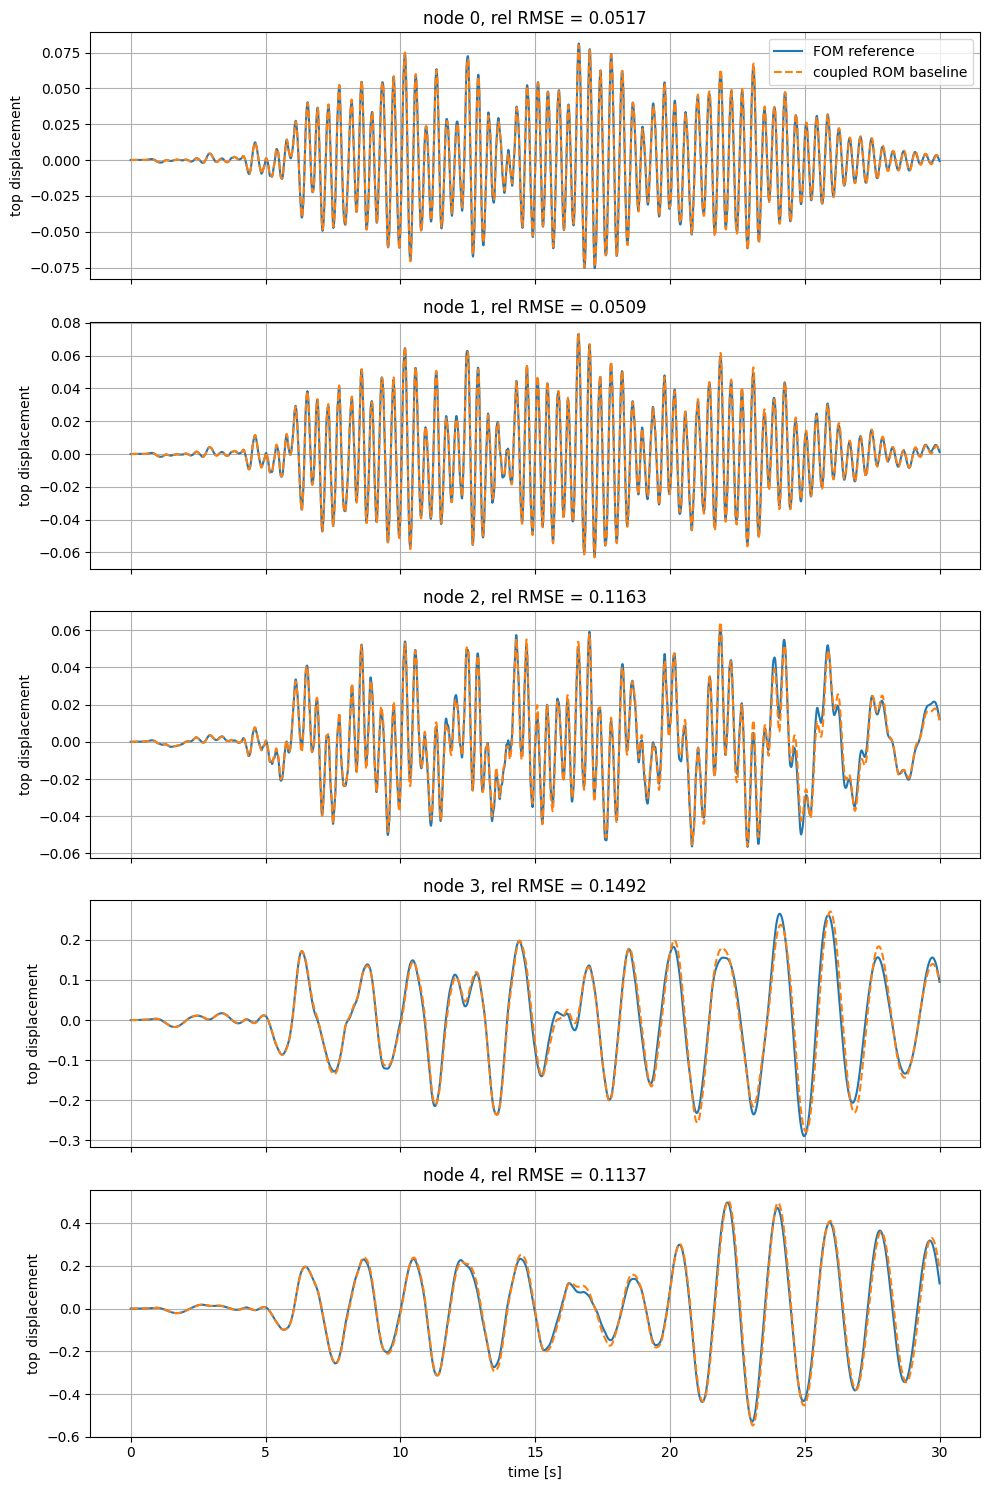

ROM baseline section moment relative RMSE: 0.13589446557492502


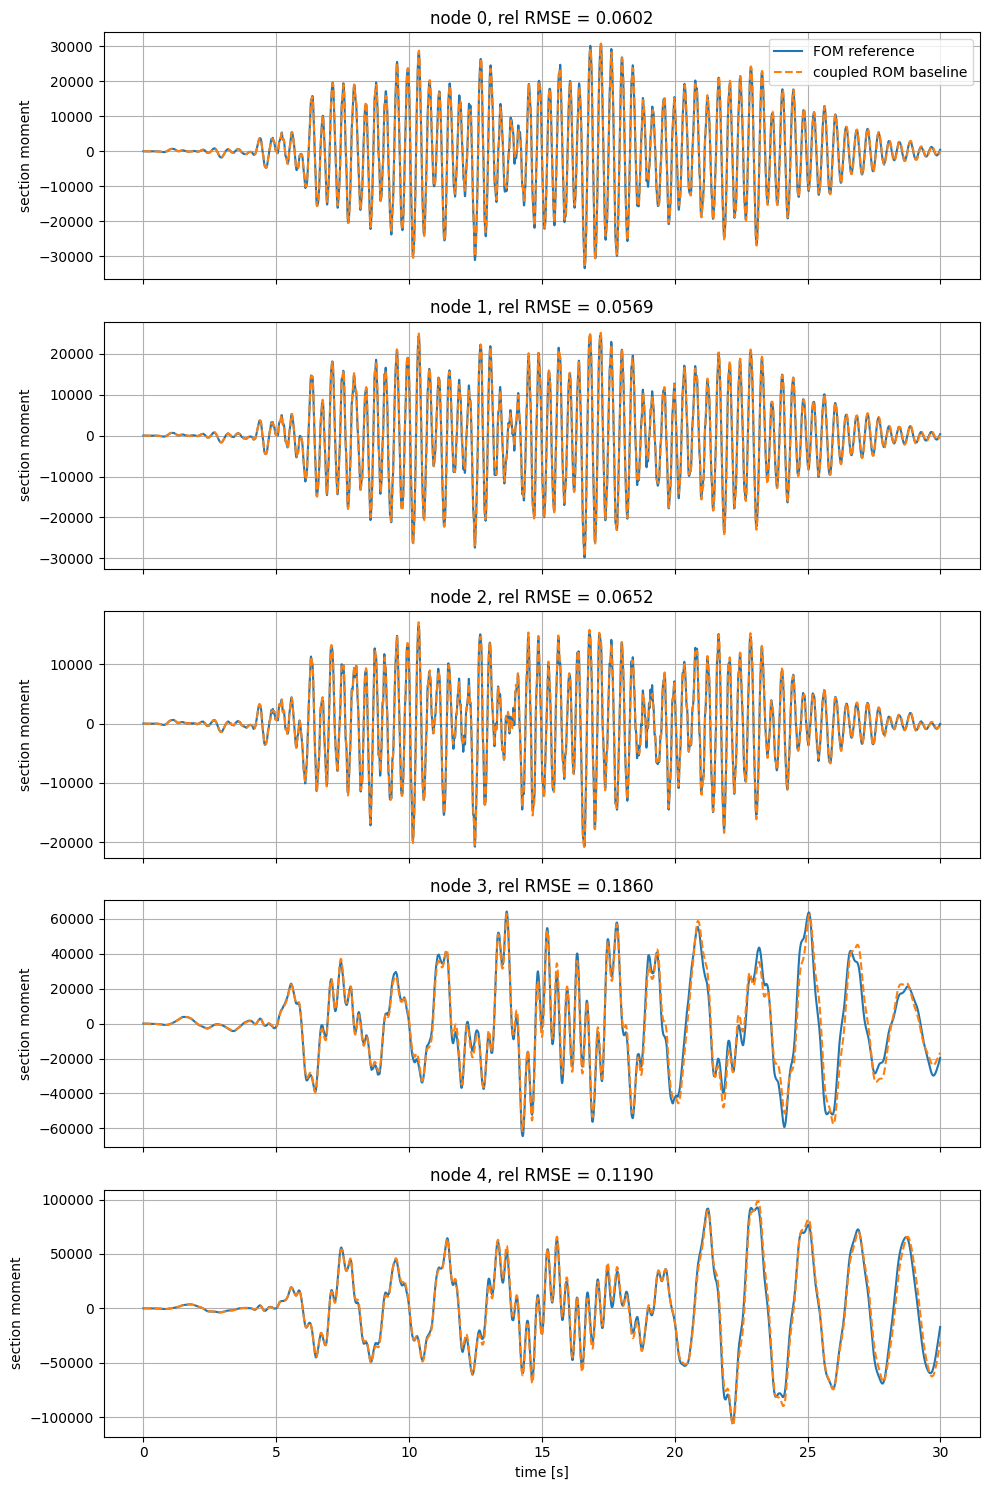

In [38]:
def rmse(y_pred, y_true):
    return float(np.sqrt(np.mean((y_pred - y_true) ** 2)))


def rel_rmse(y_pred, y_true):
    denom = float(np.sqrt(np.mean(y_true ** 2))) + 1e-12
    return rmse(y_pred, y_true) / denom


example = train_samples_np[1]
rom_baseline  = solve_coupled_rom_baseline(example)

print("Example graph N:", example["N"])
print("Component type IDs:", example["component_type_ids"])
print("FOM top response shape:", example["u_top_fom"].shape)
print("ROM baseline top displacement relative RMSE:",
      rel_rmse(rom_baseline["u_top"], example["u_top_fom"]))

time = np.arange(example["u_top_fom"].shape[0]) * example["dt"]
# node = 0

# plt.figure(figsize=(10, 4))
# plt.plot(time, example["u_top_fom"][:, node], label="FOM reference")
# plt.plot(time, rom_baseline["u_top"][:, node], "--", label="coupled ROM baseline")
# plt.xlabel("time [s]")
# plt.ylabel("top displacement")
# plt.title(f"FOM vs coupled ROM baseline, node {node}")
# plt.grid(True)
# plt.legend()
# plt.show()

N = example["N"]

fig, axes = plt.subplots(N, 1, figsize=(10, 3 * N), sharex=True)
for node in range(N):
    axes[node].plot(time, example["u_top_fom"][:, node], label="FOM reference")
    axes[node].plot(time, rom_baseline["u_top"][:, node], "--", label="coupled ROM baseline")
    axes[node].set_ylabel("top displacement")
    axes[node].set_title(
        f"node {node}, rel RMSE = "
        f"{rel_rmse(rom_baseline['u_top'][:, node], example['u_top_fom'][:, node]):.4f}"
    )
    axes[node].grid(True)

axes[0].legend()
axes[-1].set_xlabel("time [s]")

plt.tight_layout()
plt.show()



print("ROM baseline section moment relative RMSE:",
      rel_rmse(rom_baseline["moment"], example["moment_true"]))
fig, axes = plt.subplots(N, 1, figsize=(10, 3 * N), sharex=True)

if N == 1:
    axes = [axes]

for node in range(N):
    axes[node].plot(time, example["moment_true"][:, node], label="FOM reference")
    axes[node].plot(time, rom_baseline["moment"][:, node], "--", label="coupled ROM baseline")
    axes[node].set_ylabel("section moment")
    axes[node].set_title(
        f"node {node}, rel RMSE = "
        f"{rel_rmse(rom_baseline['moment'][:, node], example['moment_true'][:, node]):.4f}"
    )
    axes[node].grid(True)

axes[0].legend()
axes[-1].set_xlabel("time [s]")

plt.tight_layout()
plt.show()

## 11. Convert samples to PyTorch tensors

The GNN works directly with modal states, base acceleration at each time step, graph edges, ROM matrices, and FOM targets.

In [39]:
def compute_scales(samples):
    """
    Compute scalar normalizers from training samples.
    """
    def cat(key):
        return np.concatenate([s[key].reshape(-1) for s in samples])

    keys = [
        "q_ref",
        "qd_ref",
        "u_top_fom",
        "v_top_fom",
        "a_top_fom",
        "ag",
    ]

    scales = {}
    for key in keys:
        values = cat(key)
        scales[key] = float(np.std(values) + 1e-8)

    return scales


SCALES = compute_scales(train_samples_np)
SCALES

{'q_ref': 2.0368029942541197,
 'qd_ref': 8.174597787335674,
 'u_top_fom': 0.11019431099929111,
 'v_top_fom': 0.504742727049095,
 'a_top_fom': 4.450756621200326,
 'ag': 0.905755905230459}

In [40]:
def tensorize_sample(sample):
    """
    Convert numerical arrays in a sample to torch tensors.
    Metadata such as edges and component IDs remains unchanged.
    """
    out = dict(sample)

    float_keys = [
        "edge_attr",
        "ag",
        "u_top_fom",
        "v_top_fom",
        "a_top_fom",
        "q_ref",
        "qd_ref",
        "qdd_ref",
        "node_static",
        "Mr",
        "Cr",
        "Kr",
        "H",
        "B_cable",
        "B_ground",
        "f_cable_true",
        "B_moment",
        "G_moment",
        "moment_true",
    ]

    for key in float_keys:
        out[key] = torch.as_tensor(sample[key], dtype=torch.float32)

    out["edge_index"] = torch.as_tensor(sample["edge_index"], dtype=torch.long)

    return out


train_samples = [tensorize_sample(s) for s in train_samples_np]
val_samples = [tensorize_sample(s) for s in val_samples_np]
test_unseen = tensorize_sample(test_unseen_np)

print("Tensorized.")

Tensorized.


## 12. Differentiable matrix ROM one-step operator

For every node/component, the ROM acceleration is:

$$\ddot q_t = M_r^{-1}\left(B^{\mathrm{cable}}f^{\mathrm{cable}}_t-B^{\mathrm{ground}}a_g(t)-C_r\dot q_t-K_r q_t\right).$$

Then we use a differentiable Newmark average-acceleration step with $\beta=1/4$ and $\gamma=1/2$:

$$K_{\mathrm{eff}} = K_r + \frac{\gamma}{\beta\Delta t}C_r + \frac{1}{\beta\Delta t^2}M_r.$$

$$q_{t+1}=K_{\mathrm{eff}}^{-1}R_{\mathrm{eff}}.$$

$$\ddot q_{t+1}=\frac{1}{\beta\Delta t^2}(q_{t+1}-q_t)-\frac{1}{\beta\Delta t}\dot q_t-\left(\frac{1}{2\beta}-1\right)\ddot q_t.$$

$$\dot q_{t+1}=\dot q_t+\Delta t\left((1-\gamma)\ddot q_t+\gamma\ddot q_{t+1}\right).$$

In [41]:
def scatter_sum(src, index, dim_size):
    """
    Minimal graph aggregation using PyTorch only.

    src: [E, features]
    index: destination node indices, shape [E]
    """
    out = torch.zeros(dim_size, src.shape[-1], device=src.device, dtype=src.dtype)
    out.index_add_(0, index, src)
    return out


def matrix_rom_step(
    q,
    qdot,
    f_cable,
    ag,
    Mr,
    Cr,
    Kr,
    H,
    B_cable,
    B_ground,
    dt,
    beta=0.25,
    gamma=0.5,
):
    """
    Batched differentiable ROM step.

    Shapes:
      q, qdot: [N, r]
      f_cable: [N]
      ag: scalar tensor
      Mr, Cr, Kr: [N, r, r]
      H, B_cable, B_ground: [N, r]
    """
    force = (
        B_cable * f_cable.unsqueeze(-1)
        - B_ground * ag
    )

    qddot = torch.linalg.solve(
        Mr,
        (
            force
            - torch.einsum("nij,nj->ni", Cr, qdot)
            - torch.einsum("nij,nj->ni", Kr, q)
        ).unsqueeze(-1),
    ).squeeze(-1)

    K_eff = Kr + gamma / (beta * dt) * Cr + 1.0 / (beta * dt**2) * Mr

    rhs_eff = (
        force
        + torch.einsum(
            "nij,nj->ni",
            Mr,
            1.0 / (beta * dt**2) * q
            + 1.0 / (beta * dt) * qdot
            + (1.0 / (2.0 * beta) - 1.0) * qddot,
        )
        + torch.einsum(
            "nij,nj->ni",
            Cr,
            gamma / (beta * dt) * q
            + (gamma / beta - 1.0) * qdot
            + dt * (gamma / (2.0 * beta) - 1.0) * qddot,
        )
    )

    q_next = torch.linalg.solve(K_eff, rhs_eff.unsqueeze(-1)).squeeze(-1)

    qddot_next = (
        1.0 / (beta * dt**2) * (q_next - q)
        - 1.0 / (beta * dt) * qdot
        - (1.0 / (2.0 * beta) - 1.0) * qddot
    )

    qdot_next = qdot + dt * ((1.0 - gamma) * qddot + gamma * qddot_next)

    u_top_next = torch.einsum("ni,ni->n", H, q_next)
    v_top_next = torch.einsum("ni,ni->n", H, qdot_next)
    a_top = torch.einsum("ni,ni->n", H, qddot_next)

    return q_next, qdot_next, qddot_next, u_top_next, v_top_next, a_top

## 13. ROM-decoder GNN

The GNN predicts the missing interaction term:

$$\hat f_i^{\mathrm{cable}}(t+1).$$

Then the ROM performs the dynamic update. This is useful because the neural network does not need to learn the local structural dynamics from scratch.

In [42]:
class MLP(nn.Module):
    def __init__(self, in_dim, hidden, out_dim, n_layers=3):
        super().__init__()

        layers = []
        d = in_dim

        for _ in range(n_layers - 1):
            layers += [nn.Linear(d, hidden), nn.SiLU()]
            d = hidden

        layers.append(nn.Linear(d, out_dim))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


class MatrixROMDecoderGNN(nn.Module):
    """
    Message passing predicts net cable force at each component.
    The matrix ROM then advances each component by one time step.
    """
    def __init__(
        self,
        r_modes,
        static_dim,
        hidden=96,
        force_scale=1000.0,
        n_layers=3,
        scales=None,
    ):
        super().__init__()

        self.r_modes = r_modes
        self.static_dim = static_dim
        self.force_scale = force_scale
        self.scales = scales or {}

        node_dim = 2 * r_modes + 1 + static_dim

        self.edge_mlp = MLP(2 * node_dim + 2, hidden, hidden, n_layers=n_layers)
        self.node_mlp = MLP(node_dim + hidden, hidden, 1, n_layers=n_layers)

    def build_node_features(self, q, qdot, ag, node_static):
        qs = self.scales.get("q_ref", 1.0)
        qds = self.scales.get("qd_ref", 1.0)
        ags = self.scales.get("ag", 1.0)

        N = q.shape[0]
        ag_col = torch.ones(N, device=q.device, dtype=q.dtype) * ag

        x = torch.cat(
            [
                q / qs,
                qdot / qds,
                (ag_col / ags).unsqueeze(-1),
                node_static,
            ],
            dim=-1,
        )

        return x

    def forward(
        self,
        q,
        qdot,
        ag,
        node_static,
        edge_index,
        edge_attr,
        Mr,
        Cr,
        Kr,
        H,
        B_cable,
        B_ground,
        dt,
    ):
        N = q.shape[0]

        x = self.build_node_features(q, qdot, ag, node_static)

        src, dst = edge_index
        edge_input = torch.cat([x[src], x[dst], edge_attr], dim=-1)

        msg = self.edge_mlp(edge_input)
        agg = scatter_sum(msg, dst, N)

        f_cable_hat = self.node_mlp(torch.cat([x, agg], dim=-1)).squeeze(-1)
        f_cable_hat = self.force_scale * f_cable_hat

        q_next, qdot_next, qddot, u_next, v_next, a_top = matrix_rom_step(
            q=q,
            qdot=qdot,
            f_cable=f_cable_hat,
            ag=ag,
            Mr=Mr,
            Cr=Cr,
            Kr=Kr,
            H=H,
            B_cable=B_cable,
            B_ground=B_ground,
            dt=dt,
        )

        return {
            "q_next": q_next,
            "qdot_next": qdot_next,
            "qddot": qddot,
            "u_top_next": u_next,
            "v_top_next": v_next,
            "a_top": a_top,
            "f_cable_hat": f_cable_hat,
        }


## 14. Optional: ROM inside message passing

This is the more experimental version. Each message-passing hop predicts or corrects an interface force, then the ROM step is re-evaluated.

The notebook defines it, but trains the safer ROM-decoder GNN by default.

In [43]:
class MatrixROMInMessagePassing(nn.Module):
    """
    Experimental model:
    each message-passing hop updates a cable-force estimate and re-applies the ROM step.
    """
    def __init__(
        self,
        r_modes,
        static_dim,
        hidden=96,
        n_hops=3,
        force_scale=1000.0,
        scales=None,
    ):
        super().__init__()

        self.r_modes = r_modes
        self.static_dim = static_dim
        self.n_hops = n_hops
        self.force_scale = force_scale
        self.scales = scales or {}

        node_dim = 2 * r_modes + 1 + static_dim
        self.edge_mlp = MLP(2 * node_dim + 2, hidden, 1, n_layers=3)

    def build_node_features(self, q, qdot, ag, node_static):
        qs = self.scales.get("q_ref", 1.0)
        qds = self.scales.get("qd_ref", 1.0)
        ags = self.scales.get("ag", 1.0)

        N = q.shape[0]
        ag_col = torch.ones(N, device=q.device, dtype=q.dtype) * ag

        return torch.cat(
            [
                q / qs,
                qdot / qds,
                (ag_col / ags).unsqueeze(-1),
                node_static,
            ],
            dim=-1,
        )

    def forward(
        self,
        q,
        qdot,
        ag,
        node_static,
        edge_index,
        edge_attr,
        Mr,
        Cr,
        Kr,
        H,
        B_cable,
        B_ground,
        dt,
    ):
        N = q.shape[0]
        src, dst = edge_index

        f_cable = torch.zeros(N, device=q.device, dtype=q.dtype)

        q_hat, qdot_hat, qddot, u_hat, v_hat, a_hat = matrix_rom_step(
            q,
            qdot,
            f_cable,
            ag,
            Mr,
            Cr,
            Kr,
            H,
            B_cable,
            B_ground,
            dt,
        )

        for _ in range(self.n_hops):
            x_hat = self.build_node_features(q_hat, qdot_hat, ag, node_static)
            edge_input = torch.cat([x_hat[src], x_hat[dst], edge_attr], dim=-1)

            msg_force = self.edge_mlp(edge_input).squeeze(-1) * self.force_scale

            f_cable = f_cable + scatter_sum(
                msg_force.unsqueeze(-1),
                dst,
                N,
            ).squeeze(-1) / self.n_hops

            q_hat, qdot_hat, qddot, u_hat, v_hat, a_hat = matrix_rom_step(
                q,
                qdot,
                f_cable,
                ag,
                Mr,
                Cr,
                Kr,
                H,
                B_cable,
                B_ground,
                dt,
            )

        return {
            "q_next": q_hat,
            "qdot_next": qdot_hat,
            "qddot": qddot,
            "u_top_next": u_hat,
            "v_top_next": v_hat,
            "a_top": a_hat,
            "f_cable_hat": f_cable,
        }

## 15. Training utilities

Training is currently one-step and teacher-forced. The modal state \(q(t),\dot q(t)\) is taken from the FOM projection, and the model predicts the next modal and top-response state.

Rollout is then performed autoregressively.

In [44]:
def move_sample_to_device(sample, device):
    keys = [
        "edge_attr",
        "ag",
        "u_top_fom",
        "v_top_fom",
        "a_top_fom",
        "q_ref",
        "qd_ref",
        "qdd_ref",
        "node_static",
        "Mr",
        "Cr",
        "Kr",
        "H",
        "B_cable",
        "B_ground",
        "B_moment",
        "G_moment",
        "f_cable_true",
        "moment_true"
    ]

    out = dict(sample)

    for key in keys:
        out[key] = sample[key].to(device)

    out["edge_index"] = sample["edge_index"].to(device)

    return out


def model_step(model, sample, t):
    return model(
        q=sample["q_ref"][t],
        qdot=sample["qd_ref"][t],
        ag=sample["ag"][t+1],
        node_static=sample["node_static"],
        edge_index=sample["edge_index"],
        edge_attr=sample["edge_attr"],
        Mr=sample["Mr"],
        Cr=sample["Cr"],
        Kr=sample["Kr"],
        H=sample["H"],
        B_cable=sample["B_cable"],
        B_ground=sample["B_ground"],
        dt=sample["dt"],
    )


def one_step_loss(pred, sample, t, scales):
    q_target = sample["q_ref"][t + 1]
    qdot_target = sample["qd_ref"][t + 1]

    u_target = sample["u_top_fom"][t + 1]
    v_target = sample["v_top_fom"][t + 1]
    a_target = sample["a_top_fom"][t + 1]

    loss_q = F.mse_loss(pred["q_next"] / scales["q_ref"], q_target / scales["q_ref"])
    loss_qdot = F.mse_loss(pred["qdot_next"] / scales["qd_ref"], qdot_target / scales["qd_ref"])

    loss_u = F.mse_loss(pred["u_top_next"] / scales["u_top_fom"], u_target / scales["u_top_fom"])
    loss_v = F.mse_loss(pred["v_top_next"] / scales["v_top_fom"], v_target / scales["v_top_fom"])
    loss_a = F.mse_loss(pred["a_top"] / scales["a_top_fom"], a_target / scales["a_top_fom"])

    return loss_q + loss_qdot + loss_u + loss_v + 0.1 * loss_a


def make_val_pairs(dataset, n_checks, seed=SEED):
    rng = random.Random(seed)
    pairs = []

    for _ in range(n_checks):
        sample_id = rng.randrange(len(dataset))
        t = rng.randrange(dataset[sample_id]["q_ref"].shape[0] - 1)
        pairs.append((sample_id, t))

    return pairs


@torch.no_grad()
def evaluate_one_step(model, dataset, scales, val_pairs):
    model.eval()
    losses = []

    for sample_id, t in val_pairs:
        pred = model_step(model, dataset[sample_id], t)
        loss = one_step_loss(pred, dataset[sample_id], t, scales)
        losses.append(loss.item())

    return float(np.mean(losses))


def train_model(
    model,
    train_dataset,
    val_dataset,
    scales,
    epochs=20,
    steps_per_epoch=250,
    lr=1e-3,
    weight_decay=0.0,
    grad_clip_norm=None,
    val_checks=500,
    cosine_t_max=None,
    cosine_eta_min=1.0e-6,
):
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay,
    )

    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=cosine_t_max or epochs,
        eta_min=cosine_eta_min,
    )

    val_pairs = make_val_pairs(val_dataset, val_checks, seed=SEED)

    history = {
        "train": [],
        "val": [],
        "lr": [],
    }

    for epoch in range(1, epochs + 1):
        model.train()
        losses = []

        for _ in range(steps_per_epoch):
            sample = random.choice(train_dataset)
            t = random.randint(0, sample["q_ref"].shape[0] - 2)

            pred = model_step(model, sample, t)
            loss = one_step_loss(pred, sample, t, scales)

            optimizer.zero_grad()
            loss.backward()

            if grad_clip_norm is not None:
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip_norm)

            optimizer.step()

            losses.append(loss.item())

        val_loss = evaluate_one_step(model, val_dataset, scales, val_pairs)
        scheduler.step()
        current_lr = float(optimizer.param_groups[0]["lr"])

        history["train"].append(float(np.mean(losses)))
        history["val"].append(val_loss)
        history["lr"].append(current_lr)

        print(
            f"Epoch {epoch:03d} | "
            f"train {history['train'][-1]:.4e} | "
            f"val {val_loss:.4e} | "
            f"lr {current_lr:.3e}"
        )

    return history


## 16. Train the ROM-decoder GNN

This trains the recommended architecture:

$$\mathrm{GNN\ predicts\ cable\ force}\;\longrightarrow\;\mathrm{ROM\ step\ advances\ state}.$$

In [45]:
train_samples_dev = [move_sample_to_device(s, device) for s in train_samples]
val_samples_dev = [move_sample_to_device(s, device) for s in val_samples]
test_unseen_dev = move_sample_to_device(test_unseen, device)

static_dim = train_samples_dev[0]["node_static"].shape[1]

model = MatrixROMDecoderGNN(
    r_modes=R_MODES,
    static_dim=static_dim,
    hidden=HIDDEN,
    force_scale=1000.0,
    n_layers=N_LAYERS,
    scales=SCALES,
).to(device)

history = train_model(
    model=model,
    train_dataset=train_samples_dev,
    val_dataset=val_samples_dev,
    scales=SCALES,
    epochs=EPOCHS,
    steps_per_epoch=STEPS_PER_EPOCH,
    lr=LR,
    weight_decay=WEIGHT_DECAY,
    grad_clip_norm=GRAD_CLIP_NORM,
    val_checks=VAL_CHECKS,
    cosine_t_max=COSINE_T_MAX,
    cosine_eta_min=COSINE_ETA_MIN,
)


Epoch 001 | train 2.3065e-02 | val 2.4857e-02 | lr 5.000e-04
Epoch 002 | train 1.7303e-02 | val 1.9860e-02 | lr 4.999e-04
Epoch 003 | train 1.5419e-02 | val 1.7705e-02 | lr 4.999e-04
Epoch 004 | train 1.4358e-02 | val 1.7152e-02 | lr 4.998e-04
Epoch 005 | train 1.4566e-02 | val 1.5001e-02 | lr 4.997e-04
Epoch 006 | train 1.3991e-02 | val 1.5006e-02 | lr 4.995e-04
Epoch 007 | train 1.3859e-02 | val 1.5384e-02 | lr 4.993e-04
Epoch 008 | train 1.2306e-02 | val 1.4265e-02 | lr 4.991e-04
Epoch 009 | train 1.2650e-02 | val 1.3498e-02 | lr 4.989e-04
Epoch 010 | train 1.2298e-02 | val 1.2801e-02 | lr 4.986e-04
Epoch 011 | train 1.1894e-02 | val 1.3738e-02 | lr 4.983e-04
Epoch 012 | train 1.1895e-02 | val 1.4717e-02 | lr 4.980e-04
Epoch 013 | train 1.1664e-02 | val 1.2330e-02 | lr 4.977e-04
Epoch 014 | train 1.1808e-02 | val 1.3633e-02 | lr 4.973e-04
Epoch 015 | train 1.1439e-02 | val 1.3346e-02 | lr 4.969e-04
Epoch 016 | train 1.1470e-02 | val 1.2498e-02 | lr 4.965e-04
Epoch 017 | train 1.1974

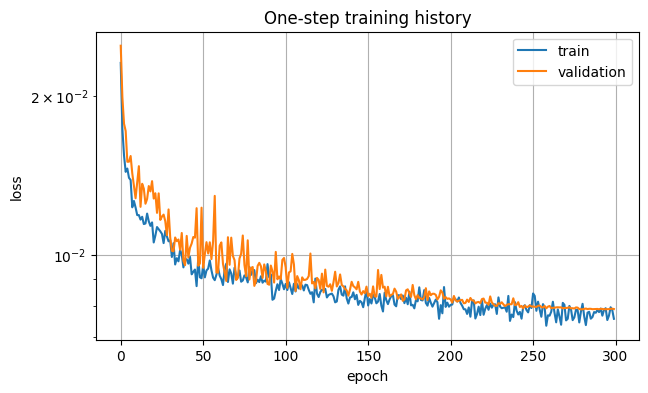

In [46]:
plt.figure(figsize=(7, 4))
plt.semilogy(history["train"], label="train")
plt.semilogy(history["val"], label="validation")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.title("One-step training history")
plt.grid(True)
plt.legend()
plt.show()

## 17. Autoregressive rollout

Training used teacher forcing. Rollout is harder because the model updates its own predicted modal state.

At each step:

$$\hat q(t),\hat{\dot q}(t)\;\longrightarrow\;\hat q(t+1),\hat{\dot q}(t+1).$$

The comparison remains against the FOM reference.

In this notebook, `u_top` and `v_top` include the initial state, so they have length `T`. The diagnostic quantities `f_cable_hat` and `moment_hat` are produced from the predicted next-step state, so they have length `T-1` and should be compared with the FOM quantities at `[1:]`.

In [47]:
@torch.no_grad()
def rollout(model, sample):
    model.eval()

    T = sample["q_ref"].shape[0]

    q = sample["q_ref"][0].clone()
    qdot = sample["qd_ref"][0].clone()

    q_hist = [q.detach().cpu()]
    qdot_hist = [qdot.detach().cpu()]
    u_hist = []
    v_hist = []
    a_hist = []
    fc_hist = []
    moment_hist = []

    for t in range(T - 1):
        pred = model(
            q=q,
            qdot=qdot,
            ag=sample["ag"][t+1],
            node_static=sample["node_static"],
            edge_index=sample["edge_index"],
            edge_attr=sample["edge_attr"],
            Mr=sample["Mr"],
            Cr=sample["Cr"],
            Kr=sample["Kr"],
            H=sample["H"],
            B_cable=sample["B_cable"],
            B_ground=sample["B_ground"],
            dt=sample["dt"],
        )

        q = pred["q_next"]
        qdot = pred["qdot_next"]

        q_hist.append(q.detach().cpu())
        qdot_hist.append(qdot.detach().cpu())

        u_hist.append(pred["u_top_next"].detach().cpu())
        v_hist.append(pred["v_top_next"].detach().cpu())
        a_hist.append(pred["a_top"].detach().cpu())
        fc_hist.append(pred["f_cable_hat"].detach().cpu())

        moment_hat = (
            torch.sum(pred["qddot"] * sample["B_moment"], dim=1)
            + sample["ag"][t+1] * sample["G_moment"]
        )
        
        moment_hist.append(moment_hat.detach().cpu())

    q_hist = torch.stack(q_hist, dim=0).numpy()
    qdot_hist = torch.stack(qdot_hist, dim=0).numpy()

    u0 = sample["u_top_fom"][0].detach().cpu().numpy()
    v0 = sample["v_top_fom"][0].detach().cpu().numpy()

    u_hist = np.vstack([u0[None, :], torch.stack(u_hist, dim=0).numpy()])
    v_hist = np.vstack([v0[None, :], torch.stack(v_hist, dim=0).numpy()])
    a_hist = torch.stack(a_hist, dim=0).numpy()
    fc_hist = torch.stack(fc_hist, dim=0).numpy()
    moment_hist = torch.stack(moment_hist, dim=0).numpy()

    return {
        "q": q_hist,
        "qdot": qdot_hist,
        "u_top": u_hist,
        "v_top": v_hist,
        "a_top": a_hist,
        "f_cable_hat": fc_hist,
        "moment_hat": moment_hist,
    }


def rollout_metrics(roll, sample):
    u_true = sample["u_top_fom"].detach().cpu().numpy()
    v_true = sample["v_top_fom"].detach().cpu().numpy()
    moment_true = sample["moment_true"].detach().cpu().numpy()

    return {
        "u_rmse": rmse(roll["u_top"], u_true),
        "u_rel_rmse": rel_rmse(roll["u_top"], u_true),
        "v_rmse": rmse(roll["v_top"], v_true),
        "v_rel_rmse": rel_rmse(roll["v_top"], v_true),
        "moment_rmse": rmse(roll["moment_hat"], moment_true[1:]),
        "moment_rel_rmse": rel_rmse(roll["moment_hat"], moment_true[1:]),
    }

## 18. Test on an unseen-size configuration

The model was trained on graphs with 3–8 components. Here we test it on 9 components.

Training graph sizes actually sampled: [8, 5, 5, 5, 5, 5, 6, 5, 5, 3, 6, 8, 8, 4, 3, 7, 3, 3, 5, 7, 7, 6, 4, 6, 7, 7, 4, 8, 8, 3, 8, 4, 6, 5, 4, 5, 5, 5, 8, 8, 3, 7, 4, 5, 7, 4, 3, 4, 6, 7, 4, 3, 7, 4, 5, 7, 5, 4, 4, 6, 8, 7, 7, 3, 7, 6, 8, 5, 7, 4, 4, 7, 4, 3, 3, 7, 6, 8, 7, 8, 6, 7, 6, 8, 3, 8, 6, 8, 6, 5, 4, 3, 4, 4, 7, 5, 3, 4, 3, 8]
Unique training graph sizes: [3, 4, 5, 6, 7, 8]
Test graph size: 9
This is size-extrapolation: the test graph has more components than any training graph.
Test component type sequence: [2 2 2 0 1 2 0 2 2]


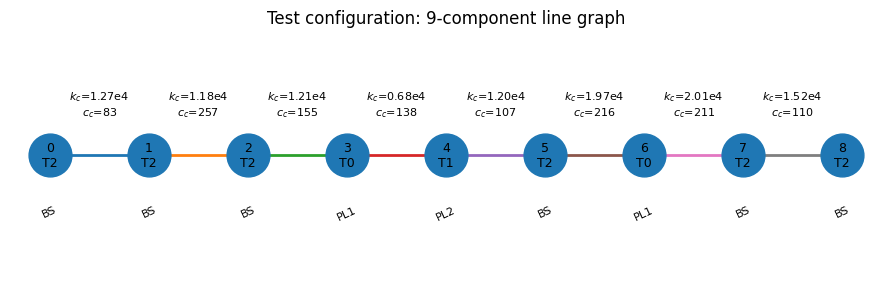

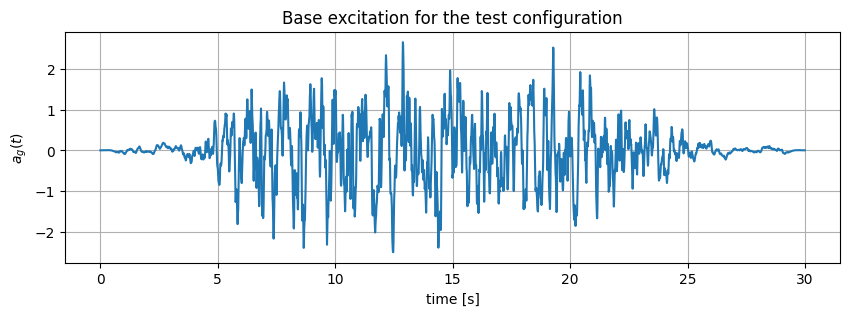

In [48]:
# ============================================================
# Visualize the unseen test configuration before rollout
# ============================================================

def short_component_name(name):
    """
    Shorten component names for plot labels.
    """
    if "Transformer" in name:
        return "Transformer-like"
    if "Breaker" in name:
        return "Breaker-like"
    if "Reactor" in name:
        return "Reactor-like"
    return name


def plot_graph_configuration(sample, component_library, title="Graph configuration"):
    """
    Visualize the line graph:
      - nodes = components
      - edges = cable links
      - node labels = component index and type
      - edge labels = cable stiffness and damping
    """
    N = sample["N"]
    component_type_ids = sample["component_type_ids"]
    edges = sample["edges"]
    kc = sample["kc"]
    cc = sample["cc"]

    x = np.arange(N)
    y = np.zeros(N)

    fig_width = max(10, 1.25 * N)
    plt.figure(figsize=(fig_width, 3.2))

    # Draw cable links
    for e, (i, j) in enumerate(edges):
        plt.plot([x[i], x[j]], [y[i], y[j]], linewidth=2, zorder=1)

        xm = 0.5 * (x[i] + x[j])
        ym = 0.13

        plt.text(
            xm,
            ym,
            f"$k_c$={kc[e]/1e4:.2f}e4\n$c_c$={cc[e]:.0f}",
            ha="center",
            va="bottom",
            fontsize=8,
        )

    # Draw component nodes
    plt.scatter(x, y, s=950, zorder=2)

    for i in range(N):
        type_id = int(component_type_ids[i])
        comp_name = short_component_name(component_library[type_id].name)

        plt.text(
            x[i],
            y[i],
            f"{i}\nT{type_id}",
            ha="center",
            va="center",
            fontsize=9,
        )

        plt.text(
            x[i],
            -0.18,
            comp_name,
            ha="center",
            va="top",
            fontsize=8,
            rotation=25,
        )

    plt.title(title)
    plt.ylim(-0.45, 0.45)
    plt.axis("off")
    plt.show()


def plot_base_excitation(sample, title="Base excitation"):
    """
    Plot the ground acceleration used in the test configuration.
    """
    ag = sample["ag"]

    if torch.is_tensor(ag):
        ag = ag.detach().cpu().numpy()

    time = np.arange(len(ag)) * sample["dt"]

    plt.figure(figsize=(10, 3))
    plt.plot(time, ag)
    plt.xlabel("time [s]")
    plt.ylabel("$a_g(t)$")
    plt.title(title)
    plt.grid(True)
    plt.show()


# Print whether the test graph is unseen by size
train_sizes = [s["N"] for s in train_samples_np]
test_size = test_unseen_np["N"]

print("Training graph sizes actually sampled:", train_sizes)
print("Unique training graph sizes:", sorted(set(train_sizes)))
print("Test graph size:", test_size)

if test_size > max(train_sizes):
    print("This is size-extrapolation: the test graph has more components than any training graph.")
elif test_size not in set(train_sizes):
    print("This exact graph size was not sampled during training.")
else:
    print("This graph size was seen during training, but the exact type sequence, cables, and excitation are still new.")

print("Test component type sequence:", test_unseen_np["component_type_ids"])

plot_graph_configuration(
    test_unseen_np,
    COMPONENT_LIBRARY,
    title=f"Test configuration: {test_size}-component line graph",
)

plot_base_excitation(
    test_unseen_np,
    title="Base excitation for the test configuration",
)

Unseen test graph N: 9
{'u_rmse': 0.017026450484991074, 'u_rel_rmse': 0.14690189081333505, 'v_rmse': 0.06333205103874207, 'v_rel_rmse': 0.15402421382650786, 'moment_rmse': 3556.779052734375, 'moment_rel_rmse': 0.15749054380034194}


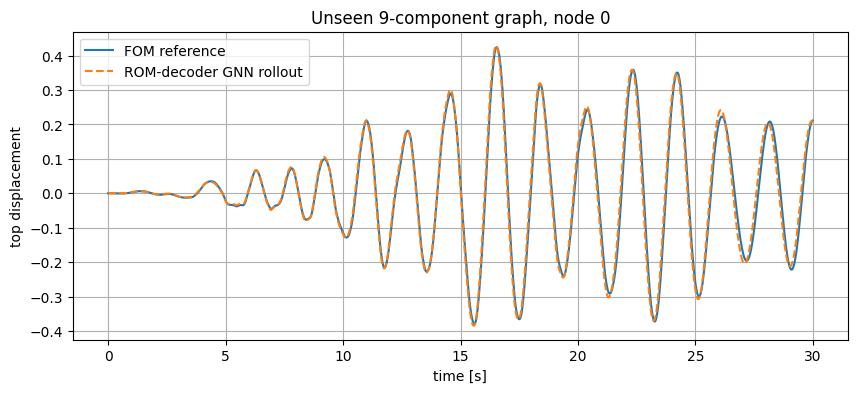

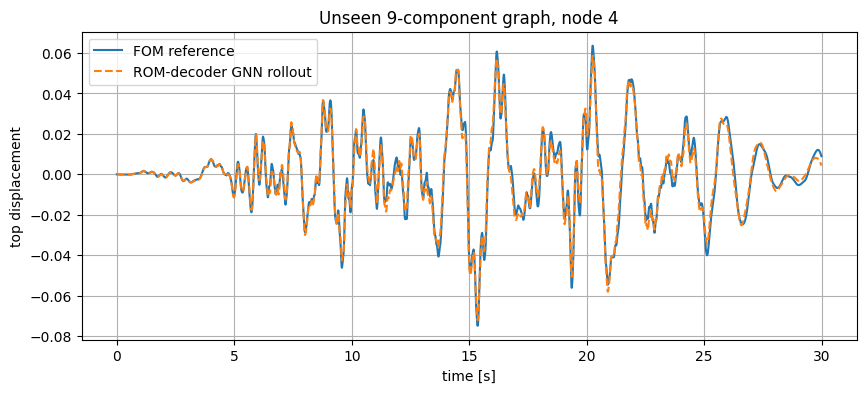

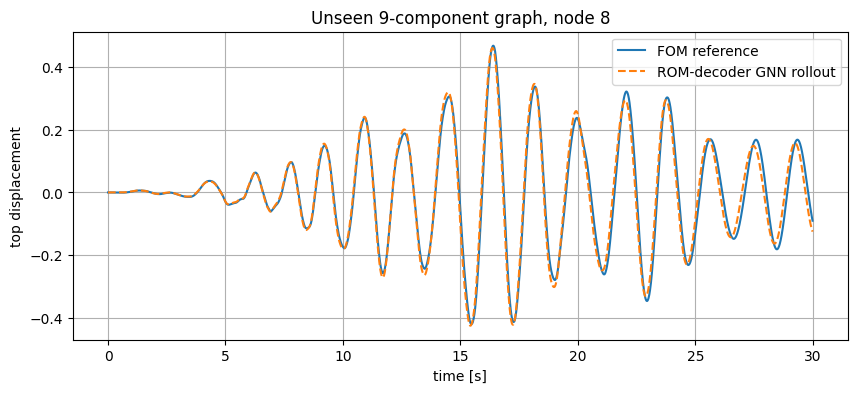

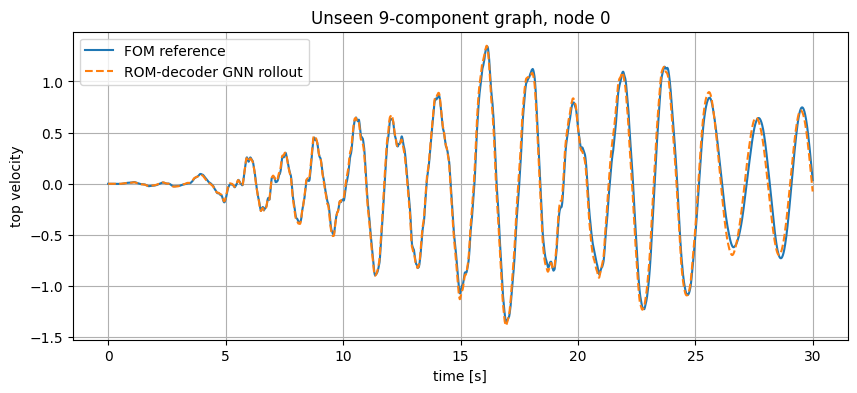

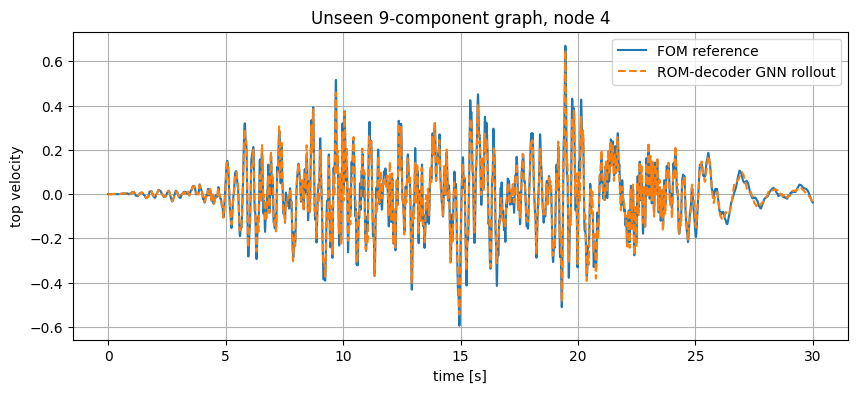

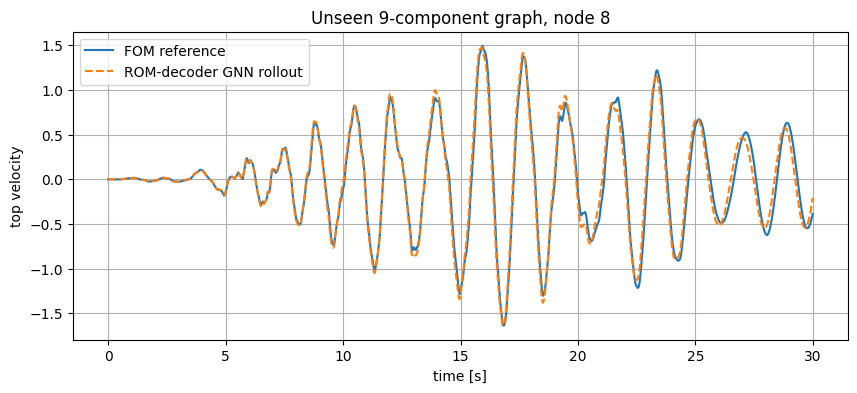

In [49]:
roll_test = rollout(model, test_unseen_dev)
metrics = rollout_metrics(roll_test, test_unseen_dev)

print("Unseen test graph N:", test_unseen_dev["N"])
print(metrics)

u_true = test_unseen_dev["u_top_fom"].detach().cpu().numpy()
time = np.arange(u_true.shape[0]) * test_unseen_dev["dt"]

for node in [0, test_unseen_dev["N"] // 2, test_unseen_dev["N"] - 1]:
    plt.figure(figsize=(10, 4))
    plt.plot(time, u_true[:, node], label="FOM reference")
    plt.plot(time, roll_test["u_top"][:, node], "--", label="ROM-decoder GNN rollout")
    plt.xlabel("time [s]")
    plt.ylabel("top displacement")
    plt.title(f"Unseen 9-component graph, node {node}")
    plt.grid(True)
    plt.legend()
    plt.show()

v_true = test_unseen_dev["v_top_fom"].detach().cpu().numpy()

for node in [0, test_unseen_dev["N"] // 2, test_unseen_dev["N"] - 1]:
    plt.figure(figsize=(10, 4))
    plt.plot(time, v_true[:, node], label="FOM reference")
    plt.plot(time, roll_test["v_top"][:, node], "--", label="ROM-decoder GNN rollout")
    plt.xlabel("time [s]")
    plt.ylabel("top velocity")
    plt.title(f"Unseen 9-component graph, node {node}")
    plt.grid(True)
    plt.legend()
    plt.show()

## 19. Cable-force and Section-moment diagnostic

This diagnostic is not used for training.

The true physical cable force is computed from the FOM top displacement and velocity. The learned force does not have to match it perfectly, because the model may use the force as an effective correction. However, if it is close, that is a useful interpretability result.

The section moment is reconstructed from the predicted modal acceleration:

$$\hat m_i(t+1)=\hat{\ddot q}_i(t+1)^T B_i^{\mathrm{moment}}+a_g(t+1)G_i^{\mathrm{moment}}.$$

Both `f_cable_hat` and `moment_hat` correspond to predicted time steps `1...T-1`, so they are compared with `f_cable_true[1:]` and `moment_true[1:]`.

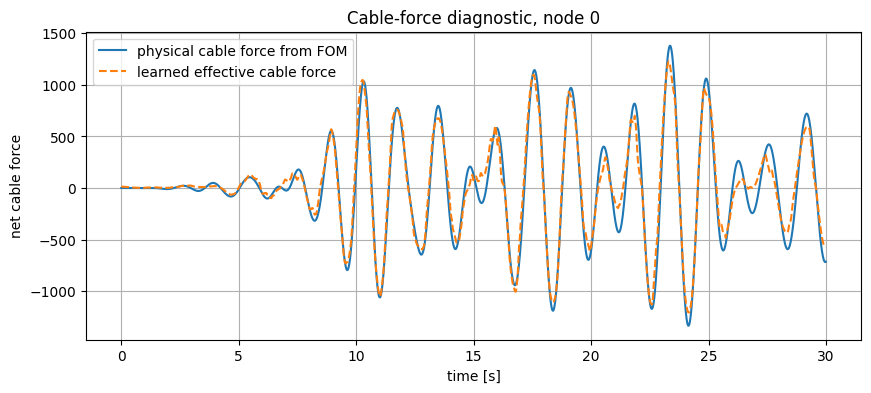

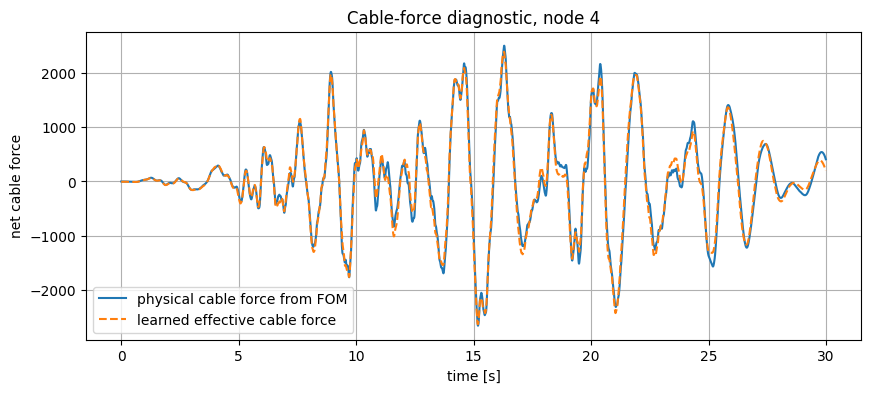

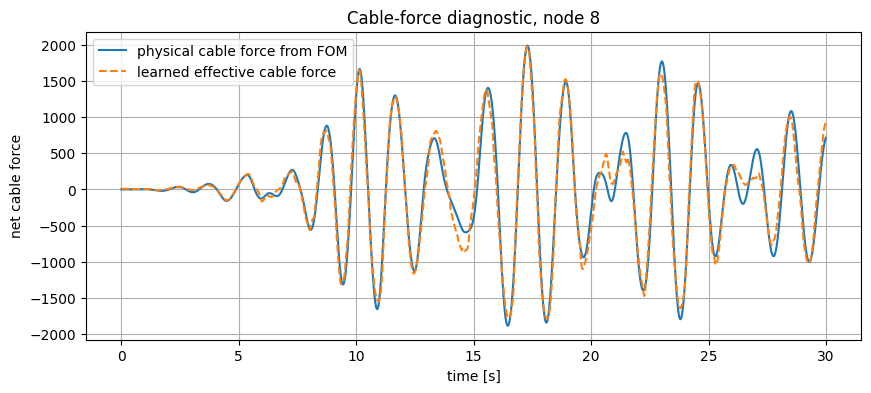

In [50]:
f_cable_true = test_unseen_dev["f_cable_true"].detach().cpu().numpy()

# Rollout force predictions correspond to physical time steps t=1...T-1.
fc_hat = roll_test["f_cable_hat"]

time_force = time[1:]

for node in [0, test_unseen_dev["N"] // 2, test_unseen_dev["N"] - 1]:
    plt.figure(figsize=(10, 4))
    plt.plot(time_force, f_cable_true[1:, node], label="physical cable force from FOM")
    plt.plot(time_force, fc_hat[:, node], "--", label="learned effective cable force")
    plt.xlabel("time [s]")
    plt.ylabel("net cable force")
    plt.title(f"Cable-force diagnostic, node {node}")
    plt.grid(True)
    plt.legend()
    plt.show()

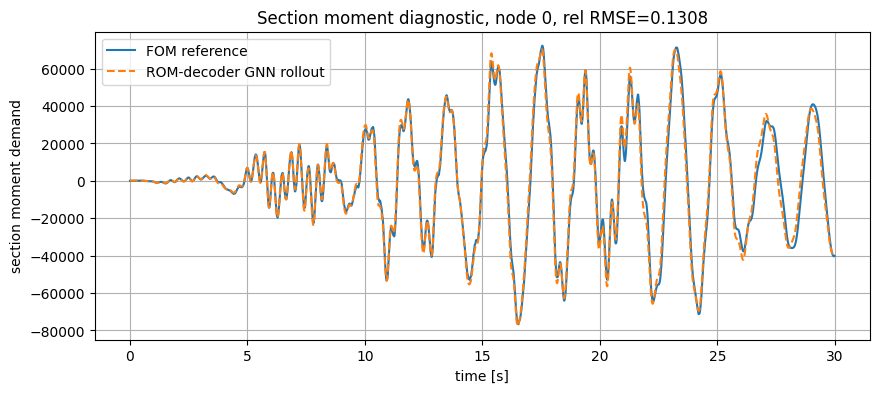

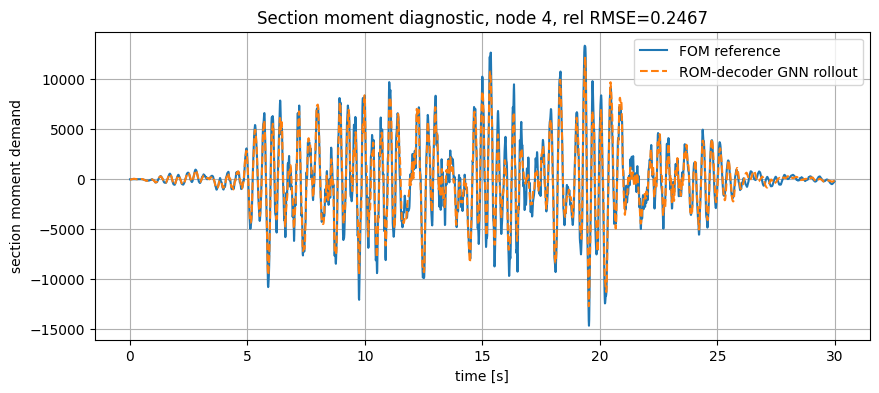

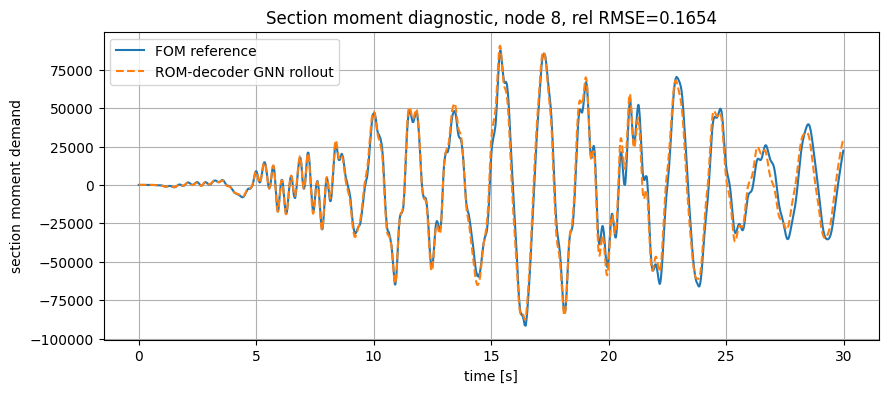

In [51]:
moment_true = test_unseen_dev["moment_true"].detach().cpu().numpy()
moment_hat = roll_test["moment_hat"]

time_moment = time[1:]

for node in [0, test_unseen_dev["N"] // 2, test_unseen_dev["N"] - 1]:
    plt.figure(figsize=(10, 4))
    plt.plot(time_moment, moment_true[1:, node], label="FOM reference")
    plt.plot(time_moment, moment_hat[:, node], "--", label="ROM-decoder GNN rollout")
    plt.xlabel("time [s]")
    plt.ylabel("section moment demand")
    plt.title(
        f"Section moment diagnostic, node {node}, "
        f"rel RMSE={rel_rmse(moment_hat[:, node], moment_true[1:, node]):.4f}"
    )
    plt.grid(True)
    plt.legend()
    plt.show()

## 20. Optional: train the ROM-in-message-passing model

This cell is off by default. Use it after the ROM-decoder GNN is working.

In [52]:
TRAIN_ROM_IN_MESSAGE_PASSING = False

if TRAIN_ROM_IN_MESSAGE_PASSING:
    model_mp = MatrixROMInMessagePassing(
        r_modes=R_MODES,
        static_dim=static_dim,
        hidden=HIDDEN,
        n_hops=3,
        force_scale=1000.0,
        scales=SCALES,
    ).to(device)

    history_mp = train_model(
        model=model_mp,
        train_dataset=train_samples_dev,
        val_dataset=val_samples_dev,
        scales=SCALES,
        epochs=EPOCHS,
        steps_per_epoch=STEPS_PER_EPOCH,
        lr=1e-3,
    )

    roll_mp = rollout(model_mp, test_unseen_dev)
    print(rollout_metrics(roll_mp, test_unseen_dev))
    
    print("Unseen test graph N:", test_unseen_dev["N"])


    u_true = test_unseen_dev["u_top_fom"].detach().cpu().numpy()
    # Rollout top displacement predictions are available for t=0...T-1.
    time = np.arange(u_true.shape[0]) * test_unseen_dev["dt"]

    for node in [0, test_unseen_dev["N"] // 2, test_unseen_dev["N"] - 1]:
        plt.figure(figsize=(10, 4))
        plt.plot(time, u_true[:, node], label="FOM reference")
        plt.plot(time, roll_test["u_top"][:, node], "--", label="ROM-decoder GNN rollout")
        plt.plot(time, roll_mp["u_top"][:, node], "-.", label="ROM-in-MP GNN rollout")
        plt.xlabel("time [s]")
        plt.ylabel("top displacement")
        plt.title(f"Unseen 9-component graph, node {node}")
        plt.grid(True)
        plt.legend()
        plt.show()


    f_cable_true = test_unseen_dev["f_cable_true"].detach().cpu().numpy()
    # Rollout force predictions are available for t=0...T-2.
    fc_hat = roll_test["f_cable_hat"]
    fc_hat_mp = roll_mp["f_cable_hat"]
    time_force = time[1:]

    for node in [0, test_unseen_dev["N"] // 2, test_unseen_dev["N"] - 1]:
        plt.figure(figsize=(10, 4))
        plt.plot(time_force, f_cable_true[1:, node], label="physical cable force from FOM")
        plt.plot(time_force, fc_hat[:, node], "--", label="learned effective cable force")
        plt.plot(time_force, fc_hat_mp[:, node], "-.", label="ROM-in-MP GNN rollout")
        plt.xlabel("time [s]")
        plt.ylabel("net cable force")
        plt.title(f"Cable-force diagnostic, node {node}")
        plt.grid(True)
        plt.legend()
        plt.show()


else:
    print("Skipped. Set TRAIN_ROM_IN_MESSAGE_PASSING = True to train this model.")

Skipped. Set TRAIN_ROM_IN_MESSAGE_PASSING = True to train this model.


## 21. How to replace the beam FOM by real component FE models

The beam FOMs are only placeholders.

For a real component, you need to provide \(M_i\), \(C_i\), \(K_i\), the top/interface DOF, and the ground-acceleration influence vector \(r_i\).

The function to replace is:

```python
build_component_fom(comp)
```

It should return the same dictionary:

```python
{
    "M": M,
    "C": C,
    "K": K,
    "top_dof": top_dof,
    "r": r,
    "freqs_hz": freqs_hz,
}
```

Everything downstream remains conceptually unchanged.

## 22. Important modeling notes

1. The ROM is used at every time step. It is not used once per batch.
2. The GNN does not replace the ROM. The GNN predicts graph/interface forces.
3. The FOM remains the reference solution.
4. The modal state must be available or estimated. In this notebook, it is available because the FOM simulations are projected onto the ROM basis.
5. The current ROM step uses differentiable Newmark average acceleration. For production, you may still compare it with an exact discrete state-space update.
6. `moment_true` and `moment_hat` are diagnostic quantities in the current pipeline. They are not included in the loss unless an explicit moment loss is added later.
7. The section moment depends on the definition of `Moment_section_node`, the height direction `height_axis`, and the consistency of Abaqus node coordinates with the selected DOF direction.

In [53]:
du_all = []

for sample in train_samples_np:
    u = sample["u_top_fom"]
    for i, j in sample["edges"]:
        du_all.append(u[:, j] - u[:, i])

du_all = np.concatenate(du_all)

print("du RMS:", np.sqrt(np.mean(du_all**2)))
print("du 90%:", np.percentile(np.abs(du_all), 90))
print("du 95%:", np.percentile(np.abs(du_all), 95))
print("du max:", np.max(np.abs(du_all)))

du RMS: 0.0747460282018273
du 90%: 0.1237529137021363
du 95%: 0.1663466007426284
du max: 0.5885308707012024
